In [ ]:
import warnings, re, os, glob, zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from IPython.display import display, Markdown, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PALETTE = ["#A8DADC", "#F4A9B8", "#BDB2FF", "#FFD6A5", "#CAFFBF",
           "#9BF6FF", "#FFC6FF", "#FDFFB6", "#A0C4FF", "#FFADAD"]
ACCENT = "#7B6FD0"

sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.1)
plt.rcParams.update({
    "figure.figsize": (11, 6), "figure.dpi": 100,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
px.defaults.template = "plotly_white"
px.defaults.color_discrete_sequence = PALETTE

FIGS = {}


def style_fig(fig, title, height=520):
    fig.update_layout(title=dict(text=f"<b>{title}</b>", x=0.02, font=dict(size=20)))
    fig.update_layout(font=dict(family="Arial", size=14), height=height)
    fig.update_layout(margin=dict(l=60, r=30, t=80, b=60))
    fig.update_layout(plot_bgcolor="white", paper_bgcolor="white")
    fig.update_xaxes(showgrid=False, linecolor="#999")
    fig.update_yaxes(gridcolor="#eee")
    return fig


def section(msg):
    display(HTML(f"<h3 style='color:{ACCENT};margin-bottom:4px'>{msg}</h3>"))


def na(msg):
    print(f"⚠️ Not available: {msg}")


print("✅ Libraries loaded and theme set.")

✅ Libraries loaded and theme set.


In [ ]:
import subprocess, sys

IN_COLAB = False
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    pass

csv_path = None

# ---- Option A: download directly from Kaggle (no login needed for public datasets) ----
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub
    folder = kagglehub.dataset_download("ahbab911/top-250-korean-dramas-kdrama-dataset")
    found = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    if found:
        csv_path = max(found, key=os.path.getsize)
        print(f"Downloaded from Kaggle: {csv_path}")
except Exception as e:
    print("Kaggle download did not work, falling back to upload. Reason:", str(e)[:150])

# ---- Option B: upload the CSV manually ----
if csv_path is None and IN_COLAB:
    print("Please choose your Kaggle K-Drama CSV file...")
    uploaded = files.upload()
    csv_files = [n for n in uploaded if n.lower().endswith(".csv")]
    if csv_files:
        csv_path = max(csv_files, key=lambda n: len(uploaded[n]))

# ---- Option C: a CSV already sitting in the folder ----
if csv_path is None:
    candidates = [p for p in glob.glob("*.csv") + glob.glob("/content/*.csv") if "cleaned" not in p.lower()]
    if candidates:
        csv_path = candidates[0]
        print(f"Using CSV found in the folder: {csv_path}")

if csv_path is None:
    raise FileNotFoundError("No CSV found. Download it from Kaggle, re-run this cell and upload it.")


def read_csv_robust(path):
    last_error = None
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        for kw in ({}, {"sep": None, "engine": "python"}):
            try:
                return pd.read_csv(path, encoding=enc, **kw)
            except Exception as e:
                last_error = e
    raise last_error


df = read_csv_robust(csv_path)
df.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in df.columns]
df_raw = df.copy(deep=True)
print(f"Loaded '{csv_path}'  ->  {df.shape[0]:,} rows x {df.shape[1]} columns")
print("A copy of the original data is stored in df_raw and will never be changed.")

100%|██████████| 89.9k/89.9k [00:00<00:00, 35.0MB/s]

Extracting files...
Downloaded from Kaggle: /root/.cache/kagglehub/datasets/ahbab911/top-250-korean-dramas-kdrama-dataset/versions/1/kdrama.csv
Loaded '/root/.cache/kagglehub/datasets/ahbab911/top-250-korean-dramas-kdrama-dataset/versions/1/kdrama.csv'  ->  250 rows x 17 columns
A copy of the original data is stored in df_raw and will never be changed.


In [ ]:
section("First 10 rows")
display(df.head(10))

section("Dimensions & column names")
print(f"Rows: {df.shape[0]:,}   |   Columns: {df.shape[1]}")
print("Columns:", list(df.columns))

section("Data types, missing values and unique counts")
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(info)

section("Duplicate records")
print(f"Fully duplicated rows: {df.duplicated().sum():,}")

section("Automatic column type detection")
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"🔢 Numerical columns ({len(num_cols)}): {num_cols}")
print(f"🔤 Categorical / text columns ({len(cat_cols)}): {cat_cols}")
print("\nNote: some numbers may be stored as text (for example '16 episodes'). We fix that in Section 3.")

,Name,Aired Date,Year of release,Original Network,Aired On,Number of Episodes,Duration,Content Rating,Rating,Synopsis,Genre,Tags,Director,Screenwriter,Cast,Production companies,Rank
0,Move to Heaven,"May 14, 2021",2021,Netflix,Friday,10,52 min.,18+ Restricted (violence & profanity),9.20,Geu Roo is a young autistic man. He works for ...,"Life, Drama, Family","Autism, Uncle-Nephew Relationship, Death, Sava...",Kim Sung Ho,Yoon Ji Ryun,"Lee Je Hoon, Tang Jun Sang, Hong Seung Hee, Ju...","Page One Film, Number Three Pictures",#1
1,Flower of Evil,"Jul 29, 2020 - Sep 23, 2020",2020,tvN,"Wednesday, Thursday",16,1 hr. 10 min.,15+ - Teens 15 or older,9.10,Although Baek Hee Sung is hiding a dark secret...,"Thriller, Romance, Crime, Melodrama","Married Couple, Deception, Suspense, Family Se...","Kim Chul Gyu, Yoon Jong Ho",Yoo Jung Hee,"Lee Joon Gi, Moon Chae Won, Jang Hee Jin, Seo ...",Monster Union,#2
2,Hospital Playlist,"Mar 12, 2020 - May 28, 2020",2020,"Netflix, tvN",Thursday,12,1 hr. 30 min.,15+ - Teens 15 or older,9.10,The stories of people going through their days...,"Friendship, Romance, Life, Medical","Strong Friendship, Multiple Mains, Best Friend...",Shin Won Ho,Lee Woo Jung,"Jo Jung Suk, Yoo Yeon Seok, Jung Kyung Ho, Kim...","Egg Is Coming, CJ ENM",#3
3,Hospital Playlist 2,"Jun 17, 2021 - Sep 16, 2021",2021,"Netflix, tvN",Thursday,12,1 hr. 40 min.,15+ - Teens 15 or older,9.10,Everyday is extraordinary for five doctors and...,"Friendship, Romance, Life, Medical","Workplace, Strong Friendship, Best Friends, Mu...",Shin Won Ho,Lee Woo Jung,"Jo Jung Suk, Yoo Yeon Seok, Jung Kyung Ho, Kim...","Egg Is Coming, CJ ENM",#4
4,My Mister,"Mar 21, 2018 - May 17, 2018",2018,tvN,"Wednesday, Thursday",16,1 hr. 17 min.,15+ - Teens 15 or older,9.10,Park Dong Hoon is a middle-aged engineer who i...,"Psychological, Life, Drama, Family","Age Gap, Nice Male Lead, Strong Female Lead, H...","Kim Won Suk, Kim Sang Woo",Park Hae Young,"Lee Sun Kyun, IU, Park Ho San, Song Sae Byuk, ...",Chorokbaem Media,#5
5,Reply 1988,"Nov 6, 2015 - Jan 16, 2016",2015,tvN,"Friday, Saturday",20,1 hr. 40 min.,15+ - Teens 15 or older,9.10,"Five childhood friends, who all live in the sa...","Comedy, Romance, Youth, Family","Neighbors, Slice Of Life, Childhood Friends, M...","Shin Won Ho, Yoo Hak Chan",Lee Woo Jung,"Lee Hye Ri, Go Kyung Pyo, Ryu Joon Yeol, Park ...",CJ ENM,#6
6,Weak Hero Class 1,"Nov 18, 2022",2022,Wavve,Friday,8,40 min.,18+ Restricted (violence & profanity),9.10,Yeon Shi Eun is a model student who ranks at t...,"Action, Youth, Drama\r","Bromance, Smart Male Lead, Violence, School Bu...",You Su Min,Jun Hee Han,"Park Ji Hoon, Choi Hyun Wook, Hong Kyung, Kim ...",PlayList Global,#7
7,Prison Playbook,"Nov 22, 2017 - Jan 18, 2018",2017,"Netflix, tvN","Wednesday, Thursday",16,1 hr. 32 min.,15+ - Teens 15 or older,9.10,"Kim Je Hyuk, a famous baseball player, is arre...","Comedy, Crime, Life, Drama","Prison, Bromance, Wrongfully Accused, Life Les...",Shin Won Ho,"Jung Bo Hoon, Lee Woo Jung","Park Hae Soo, Jung Kyung Ho, Krystal Jung, Im ...",tvN,#8
8,Alchemy of Souls,"Jun 18, 2022 - Aug 28, 2022",2022,"Netflix, tvN","Saturday, Sunday",20,1 hr. 20 min.,15+ - Teens 15 or older,9.00,Set in a fictional country called Daeho that d...,"Action, Historical, Romance, Fantasy","Magical Power, Supernatural, Transmigration, S...",Park Joon Hwa,"Hong Jung Eun, Hong Mi Ran","Lee Jae Wook, Jung So Min, Hwang Hyun Min, Shi...","Studio Dragon, High Quality",#9
9,Extraordinary Attorney Woo,"Jun 29, 2022 - Aug 18, 2022",2022,"ENA, Netflix","Wednesday, Thursday",16,1 hr. 17 min.,15+ - Teens 15 or older,9.00,"Diagnosed with autism spectrum disorder, 27-ye...","Law, Romance, Life, Drama","Autistic Female Lead, Autism, Attorney Female...",Yoo In Shik,Moon Ji Won,"Park Eun Bin, Kang Tae Oh, Kang Ki Young, Jeon...","AStory, KT Studio Genie, Nangman Crew",#10


Rows: 250   |   Columns: 17
Columns: ['Name', 'Aired Date', 'Year of release', 'Original Network', 'Aired On', 'Number of Episodes', 'Duration', 'Content Rating', 'Rating', 'Synopsis', 'Genre', 'Tags', 'Director', 'Screenwriter', 'Cast', 'Production companies', 'Rank']


,dtype,missing,missing_%,unique_values
Name,object,0,0.00,250
Aired Date,object,0,0.00,248
Year of release,int64,0,0.00,17
Original Network,object,0,0.00,45
Aired On,object,0,0.00,21
Number of Episodes,int64,0,0.00,30
Duration,object,0,0.00,38
Content Rating,object,5,2.00,4
Rating,float64,0,0.00,10
Synopsis,object,0,0.00,250


Fully duplicated rows: 0


🔢 Numerical columns (3): ['Year of release', 'Number of Episodes', 'Rating']
🔤 Categorical / text columns (14): ['Name', 'Aired Date', 'Original Network', 'Aired On', 'Duration', 'Content Rating', 'Synopsis', 'Genre', 'Tags', 'Director', 'Screenwriter', 'Cast', 'Production companies', 'Rank']

Note: some numbers may be stored as text (for example '16 episodes'). We fix that in Section 3.


In [ ]:
COLUMN_HINTS = [
    (r"^(drama.?)?(name|title)|^show", "Title of the drama (identifier)."),
    (r"year", "Year the drama was released / first aired."),
    (r"aired.?date|air.?date|release.?date|start.?date|premiere|^date", "Date range or start date when the drama aired."),
    (r"aired.?on|weekday|broadcast.?day", "Weekdays on which new episodes were broadcast."),
    (r"episode|^eps?$", "Number of episodes in the series."),
    (r"network|platform|channel|broadcaster|streaming", "TV network / streaming platform that aired the drama."),
    (r"duration|runtime|minutes", "Length of one episode (usually minutes)."),
    (r"content.?rating|certificate|age.?rating", "Age/content rating (for example 15+ Teens)."),
    (r"synopsis|plot|description|overview|summary", "Short story description (text)."),
    (r"^cast|actor|starring|main.?role|^lead", "Actors appearing in the drama."),
    (r"director", "Director(s) of the drama."),
    (r"writer|screenwriter", "Writer(s) of the drama."),
    (r"production.?compan|studio", "Production company or studio behind the drama."),
    (r"genre|categor", "Genre labels, often several per drama (for example Romance, Comedy)."),
    (r"tag|keyword", "Descriptive keywords/themes from the source website."),
    (r"popular|watcher|views|members|votes|favou?rite", "Popularity signal (can be a rank or a count)."),
    (r"^rank|ranking", "Overall rank on the source website (1 = best)."),
    (r"rating|score", "Viewer rating / score (typically on a 0-10 scale)."),
    (r"country|origin", "Country of origin."),
    (r"unnamed", "Leftover index column from a previous export."),
]


def explain_column(col):
    for pattern, meaning in COLUMN_HINTS:
        if re.search(pattern, col.lower()):
            return meaning
    return "Not recognised automatically - see the example value."


def first_example(series):
    s = series.dropna()
    if s.empty:
        return "(all missing)"
    v = str(s.iloc[0])
    return v if len(v) <= 70 else v[:67] + "..."


meaning_table = pd.DataFrame({
    "Column": df.columns,
    "Meaning": [explain_column(c) for c in df.columns],
    "Example value": [first_example(df[c]) for c in df.columns],
})
display(meaning_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Column,Meaning,Example value
Name,Title of the drama (identifier).,Move to Heaven
Aired Date,Date range or start date when the drama aired.,"May 14, 2021"
Year of release,Year the drama was released / first aired.,2021
Original Network,TV network / streaming platform that aired the drama.,Netflix
Aired On,Weekdays on which new episodes were broadcast.,Friday
Number of Episodes,Number of episodes in the series.,10
Duration,Length of one episode (usually minutes).,52 min.
Content Rating,Age/content rating (for example 15+ Teens).,18+ Restricted (violence & profanity)
Rating,Viewer rating / score (typically on a 0-10 scale).,9.2
Synopsis,Short story description (text).,Geu Roo is a young autistic man. He works for his father’s business...


In [11]:
MANUAL_COLUMNS = {}


def find_col(patterns, exclude=()):
    for pat in patterns:
        for c in df.columns:
            if c in exclude or c is None:
                continue
            if re.search(pat, c.lower()):
                return c
    return None


C = {}
C["content_rating"] = find_col([r"content.?rating", r"certificate", r"age.?rating"])
C["title"] = find_col([r"^(drama.?)?(name|title)$", r"name|title"])
C["year"] = find_col([r"year"])
C["date"] = find_col([r"aired.?date", r"air.?date", r"release.?date", r"start.?date", r"premiere", r"date"], exclude=(C["year"],))
C["rating"] = find_col([r"^(imdb.?|mdl.?|user.?|average.?)?(rating|score)s?$", r"rating|score"], exclude=(C["content_rating"],))
C["episodes"] = find_col([r"episode", r"^eps?$"])
C["network"] = find_col([r"network", r"platform", r"channel", r"broadcast", r"streaming"])
C["genre"] = find_col([r"genre", r"categor"])
C["cast"] = find_col([r"^cast", r"actor", r"starring", r"main.?role", r"^lead"])
C["director"] = find_col([r"director"])
C["popularity"] = find_col([r"popular", r"watcher", r"views", r"members", r"votes", r"favou?rite"])
C["rank"] = find_col([r"^rank", r"ranking"], exclude=(C["popularity"],))
C["duration"] = find_col([r"duration", r"runtime", r"minutes"])
C["country"] = find_col([r"country"], exclude=(C["network"],))

for role, col in MANUAL_COLUMNS.items():
    if col in df.columns:
        C[role] = col

role_table = pd.DataFrame({
    "Analysis role": list(C.keys()),
    "Detected column": [v if v else "not found" for v in C.values()],
})
display(role_table.style.hide(axis="index"))
QUESTION_NEEDS = {
    "Q1  Number of dramas": [],
    "Q2  Years with most dramas": ["year"],
    "Q3  Most popular genres": ["genre"],
    "Q4  Highest-rated dramas": ["rating", "title"],
    "Q5  Average rating": ["rating"],
    "Q6  Most episodes": ["episodes", "title"],
    "Q7  Episodes vs rating": ["episodes", "rating"],
    "Q8  Top networks": ["network"],
    "Q9  Most frequent actors": ["cast"],
    "Q10 Top directors": ["director"],
    "Q11 Genre average ratings": ["genre", "rating"],
    "Q12 Production trends": ["year"],
    "Q13 Rating vs popularity": ["rating", "popularity"],
    "Q14 Rating-to-popularity": ["rating", "popularity", "title"],
}

print("Which questions can this dataset answer?")
for q, needs in QUESTION_NEEDS.items():
    missing = [n for n in needs if not C.get(n)]
    if missing:
        print("  NO  ", q, "(missing:", ", ".join(missing) + ")")
    else:
        print("  YES ", q)

Analysis role,Detected column
content_rating,Content Rating
title,Name
year,Year of release
date,Aired Date
rating,Rating
episodes,Number of Episodes
network,Original Network
genre,Genre
cast,Cast
director,Director


Which questions can this dataset answer?
  YES  Q1  Number of dramas
  YES  Q2  Years with most dramas
  YES  Q3  Most popular genres
  YES  Q4  Highest-rated dramas
  YES  Q5  Average rating
  YES  Q6  Most episodes
  YES  Q7  Episodes vs rating
  YES  Q8  Top networks
  YES  Q9  Most frequent actors
  YES  Q10 Top directors
  YES  Q11 Genre average ratings
  YES  Q12 Production trends
  NO   Q13 Rating vs popularity (missing: popularity)
  NO   Q14 Rating-to-popularity (missing: popularity)


In [12]:
cleaning_log = []


def log_step(step, why, outcome):
    cleaning_log.append({"Step": step, "Why it matters": why, "Outcome": outcome})
    print(f"✔ {step}: {outcome}")


df = df_raw.copy(deep=True)
rows_start = len(df)

# drop leftover index columns such as 'Unnamed: 0'
for c in list(df.columns):
    if c.lower().startswith("unnamed") and pd.api.types.is_numeric_dtype(df[c]) and df[c].is_unique:
        df = df.drop(columns=c)
        log_step("Dropped index column", "A row-number column carries no information.", f"removed '{c}'")

# placeholders like N/A or - become real missing values; extra spaces removed
PLACEHOLDER = r"(?i)^\s*(?:n/?a|nan|none|null|nil|-+|\?+|unknown|not available|tbd)?\s*$"
newly_missing = 0
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    before = df[c].isna().sum()
    df[c] = df[c].map(lambda v: re.sub(r"\s+", " ", v).strip() if isinstance(v, str) else v)
    df[c] = df[c].replace(PLACEHOLDER, np.nan, regex=True)
    newly_missing += int(df[c].isna().sum() - before)

log_step("Text normalisation",
         "Extra spaces and placeholders like 'N/A' would be counted as real values.",
         f"{len(text_cols)} text columns tidied; {newly_missing:,} placeholder cells set to missing")

✔ Text normalisation: 14 text columns tidied; 0 placeholder cells set to missing


In [13]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
exact_removed = before - len(df)

near_removed = 0
if C["title"]:
    key = df[C["title"]].astype("object").str.lower().str.strip()
    extra = C["year"] or C["date"]
    if extra:
        check = pd.DataFrame({"t": key, "x": df[extra].astype("object")})
        dup_mask = check.duplicated(keep="first") & key.notna()
    else:
        dup_mask = key.duplicated(keep="first") & key.notna()
    near_removed = int(dup_mask.sum())
    df = df.loc[~dup_mask].reset_index(drop=True)

log_step("Duplicate removal", "Duplicates would double-count dramas.",
         f"{exact_removed} identical rows + {near_removed} same-title/same-year rows removed")

if C["title"]:
    no_title = int(df[C["title"]].isna().sum())
    if no_title:
        df = df.dropna(subset=[C["title"]]).reset_index(drop=True)
    log_step("Rows without a title", "A drama we cannot name cannot be ranked.", f"{no_title} rows removed")

✔ Duplicate removal: 0 identical rows + 0 same-title/same-year rows removed
✔ Rows without a title: 0 rows removed


In [14]:
def to_num(s):
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce").astype(float)
    cleaned = s.astype(str).str.replace(",", "", regex=False).str.extract(r"(-?\d+(?:\.\d+)?)")[0]
    return pd.to_numeric(cleaned, errors="coerce").astype(float)


def to_year(s):
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce").astype(float)
    y = s.astype(str).str.extract(r"((?:19|20)\d{2})")[0]
    return pd.to_numeric(y, errors="coerce").astype(float)


def to_minutes(s):
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce").astype(float)
    t = s.astype(str).str.lower()
    h = pd.to_numeric(t.str.extract(r"(\d+(?:\.\d+)?)\s*(?:hr|hour|h)")[0], errors="coerce").astype(float)
    m = pd.to_numeric(t.str.extract(r"(\d+(?:\.\d+)?)\s*(?:min|m)\b")[0], errors="coerce").astype(float)
    total = h.fillna(0) * 60 + m.fillna(0)
    total[h.isna() & m.isna()] = np.nan
    return total.fillna(to_num(s))


converted = []
for role, fn in (("rating", to_num), ("episodes", to_num), ("popularity", to_num),
                 ("rank", to_num), ("duration", to_minutes)):
    col = C.get(role)
    if col:
        old_dtype = str(df[col].dtype)
        before_missing = int(df[col].isna().sum())
        df[col] = fn(df[col])
        new_missing = int(df[col].isna().sum()) - before_missing
        converted.append(f"{col}: {old_dtype} -> float (new missing: {new_missing})")

if C["year"]:
    old_dtype = str(df[C["year"]].dtype)
    df[C["year"]] = to_year(df[C["year"]])
    if C["date"]:
        from_date = to_year(df[C["date"]])
        filled = df[C["year"]].isna() & from_date.notna()
        df.loc[filled, C["year"]] = from_date[filled]
        converted.append(f"{C['year']}: filled {int(filled.sum())} missing years from '{C['date']}'")
    converted.append(f"{C['year']}: {old_dtype} -> numeric year")
elif C["date"]:
    df["Year (derived)"] = to_year(df[C["date"]])
    C["year"] = "Year (derived)"
    converted.append(f"Created 'Year (derived)' from '{C['date']}'")

for line in converted:
    print("  -", line)
log_step("Data-type correction", "Text-formatted numbers cannot be used in maths or charts.",
         f"{len(converted)} conversions applied")

  - Rating: float64 -> float (new missing: 0)
  - Number of Episodes: int64 -> float (new missing: 0)
  - Rank: object -> float (new missing: 0)
  - Duration: object -> float (new missing: 0)
  - Year of release: filled 0 missing years from 'Aired Date'
  - Year of release: int64 -> numeric year
✔ Data-type correction: 6 conversions applied


In [15]:
def norm_key(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def harmonize_single(series):
    s = series.dropna().astype(str)
    if s.empty:
        return series, 0
    keys = s.map(norm_key)
    canon = pd.DataFrame({"k": keys, "v": s}).groupby("k")["v"].agg(lambda x: x.value_counts().idxmax())
    out = series.copy()
    out.loc[s.index] = keys.map(canon)
    return out, int(series.nunique() - out.nunique())


for role in ("content_rating", "country"):
    col = C.get(role)
    if col:
        df[col], merged = harmonize_single(df[col])
        log_step(f"Category harmonisation ({col})",
                 "Spelling/case variants split one category into many.",
                 f"{merged} variant spellings merged")

SEPARATOR = r"\s*[,;|]\s*"


def split_multi(value):
    if not isinstance(value, str):
        return []
    value = re.sub(r"[\[\]'\"]", "", value)
    parts = [p.strip() for p in re.split(SEPARATOR, value) if p.strip()]
    unique = []
    for p in parts:
        if p not in unique:
            unique.append(p)
    return unique


for role in ("genre", "network", "cast", "director"):
    col = C.get(role)
    if not col:
        continue
    lists = df[col].map(split_multi)
    items = [i for l in lists for i in l]
    if not items:
        continue
    keys = pd.Series(items).map(norm_key)
    canon = pd.DataFrame({"k": keys, "v": items}).groupby("k")["v"].agg(
        lambda x: x.value_counts().idxmax()).to_dict()
    n_before = len(set(items))
    df[col + "__list"] = lists.map(lambda l: list(dict.fromkeys(canon.get(norm_key(i), i) for i in l)))
    n_after = len({i for l in df[col + "__list"] for i in l})
    log_step(f"Multi-value split ({col})",
             "One cell can hold several values; analysis needs one value per item.",
             f"{n_before - n_after} spelling variants merged -> {n_after:,} distinct items")

✔ Category harmonisation (Content Rating): 0 variant spellings merged
✔ Multi-value split (Genre): 0 spelling variants merged -> 29 distinct items
✔ Multi-value split (Original Network): 0 spelling variants merged -> 23 distinct items
✔ Multi-value split (Cast): 0 spelling variants merged -> 829 distinct items
✔ Multi-value split (Director): 0 spelling variants merged -> 183 distinct items


In [16]:
current_year = pd.Timestamp.today().year
validation_rows = []


def validate(name, col, mask_bad):
    n_bad = int(mask_bad.sum())
    if n_bad:
        df.loc[mask_bad, col] = np.nan
    validation_rows.append({"Check": name, "Column": col, "Invalid values found": n_bad,
                            "Action": "set to missing" if n_bad else "none needed"})


if C["rating"]:
    rmax = df[C["rating"]].max()
    if 10 < rmax <= 100:
        df[C["rating"]] = df[C["rating"]] / 10
        log_step("Rating scale", "Mixed scales break comparisons.", "ratings looked 0-100, divided by 10")
    validate("Rating between 0 and 10", C["rating"],
             df[C["rating"]].notna() & ~df[C["rating"]].between(0, 10))
if C["year"]:
    validate(f"Year between 1950 and {current_year + 2}", C["year"],
             df[C["year"]].notna() & ~df[C["year"]].between(1950, current_year + 2))
if C["episodes"]:
    validate("Episodes at least 1", C["episodes"],
             df[C["episodes"]].notna() & (df[C["episodes"]] < 1))
if C["duration"]:
    validate("Duration greater than 0", C["duration"],
             df[C["duration"]].notna() & (df[C["duration"]] <= 0))
if C["popularity"]:
    validate("Popularity not negative", C["popularity"],
             df[C["popularity"]].notna() & (df[C["popularity"]] < 0))

display(pd.DataFrame(validation_rows))

# outliers with the IQR rule: flagged and KEPT, because real extremes are not errors
outlier_rows = []
outlier_bounds = {}
for role in ("rating", "episodes", "duration", "popularity"):
    col = C.get(role)
    if col and df[col].notna().sum() > 10:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outlier_bounds[col] = (lo, hi)
        n_out = int(((s < lo) | (s > hi)).sum())
        outlier_rows.append({"Column": col, "Lower fence": lo, "Upper fence": hi,
                             "Outliers": n_out, "% of rows": 100 * n_out / len(s)})
if outlier_rows:
    section("Outlier report (IQR rule)")
    display(pd.DataFrame(outlier_rows))
    print("Decision: outliers are KEPT. They are real dramas, not data errors.")

log_step("Validation and outliers", "Impossible values distort statistics.",
         f"{sum(r['Invalid values found'] for r in validation_rows)} impossible values set to missing; outliers flagged and kept")

,Check,Column,Invalid values found,Action
0,Rating between 0 and 10,Rating,0,none needed
1,Year between 1950 and 2028,Year of release,0,none needed
2,Episodes at least 1,Number of Episodes,0,none needed
3,Duration greater than 0,Duration,0,none needed


,Column,Lower fence,Upper fence,Outliers,% of rows
0,Rating,7.70,9.30,0,0.00
1,Number of Episodes,10.00,26.00,51,20.40
2,Duration,45.00,85.00,41,16.40


Decision: outliers are KEPT. They are real dramas, not data errors.
✔ Validation and outliers: 0 impossible values set to missing; outliers flagged and kept


In [17]:
POPULARITY_IS_RANK = None      # None = detect automatically; or set True / False

C["pop_score"] = None
if C["popularity"]:
    s = df[C["popularity"]].dropna()
    if POPULARITY_IS_RANK is None:
        name = C["popularity"].lower()
        POPULARITY_IS_RANK = bool(
            len(s) > 20 and ("popular" in name or "rank" in name)
            and (s % 1 == 0).all() and s.max() <= 1.5 * len(df) and s.nunique() / len(s) > 0.9
        )
    if POPULARITY_IS_RANK:
        pct = df[C["popularity"]].rank(pct=True)
        df["popularity_score"] = 1 - pct + 1 / max(len(df), 1)
        print(f"'{C['popularity']}' looks like a RANK (1 = most popular).")
        print("Created popularity_score = 1 - percentile of the rank (higher = more popular).")
    else:
        df["popularity_score"] = df[C["popularity"]]
        print(f"'{C['popularity']}' looks like a COUNT (bigger = more popular). Used as-is.")
    C["pop_score"] = "popularity_score"
    log_step("Popularity direction", "Rank and count scales point in opposite directions.",
             "rank converted to higher = more popular" if POPULARITY_IS_RANK else "count used directly")
else:
    print("No popularity column found, so questions 13 and 14 will be skipped.")

No popularity column found, so questions 13 and 14 will be skipped.


In [18]:
list_cols = [c for c in df.columns if c.endswith("__list")]
shown_cols = [c for c in df.columns if c not in list_cols]

before_after = pd.DataFrame({
    "missing BEFORE cleaning": df_raw.isna().sum(),
    "missing AFTER cleaning": df[shown_cols].isna().sum().reindex(df_raw.columns),
}).dropna(how="all")
display(before_after[(before_after > 0).any(axis=1)])

print("Rows:", rows_start, "->", len(df), "| removed:", rows_start - len(df))
log_step("Missing-value policy", "Invented values would produce fabricated findings.",
         "no imputation for analysis; each analysis uses available rows only")

TITLE, YEAR, RATING, EPS = C["title"], C["year"], C["rating"], C["episodes"]
GENRE, NETWORK, CAST, DIRECTOR = C["genre"], C["network"], C["cast"], C["director"]
POPS, DUR, RANK = C["pop_score"], C["duration"], C["rank"]
corr_cols = [c for c in (RATING, EPS, YEAR, POPS, DUR, RANK) if c]
MIN_N = max(5, int(0.01 * len(df)))
R = {}

,missing BEFORE cleaning,missing AFTER cleaning
Content Rating,5,5
Director,1,1
Screenwriter,1,1
Production companies,2,2


Rows: 250 -> 250 | removed: 0
✔ Missing-value policy: no imputation for analysis; each analysis uses available rows only


In [19]:
def pretty(frame):
    frame = frame.copy()
    for c in (YEAR, EPS):
        if c and c in frame.columns:
            frame[c] = frame[c].round().astype("Int64")
    return frame


section("Cleaning log")
display(pd.DataFrame(cleaning_log).style.hide(axis="index").set_properties(**{"text-align": "left"}))

section("Cleaned data preview")
display(pretty(df[shown_cols]).head(5))

Step,Why it matters,Outcome
Text normalisation,Extra spaces and placeholders like 'N/A' would be counted as real values.,14 text columns tidied; 0 placeholder cells set to missing
Duplicate removal,Duplicates would double-count dramas.,0 identical rows + 0 same-title/same-year rows removed
Rows without a title,A drama we cannot name cannot be ranked.,0 rows removed
Data-type correction,Text-formatted numbers cannot be used in maths or charts.,6 conversions applied
Category harmonisation (Content Rating),Spelling/case variants split one category into many.,0 variant spellings merged
Multi-value split (Genre),One cell can hold several values; analysis needs one value per item.,0 spelling variants merged -> 29 distinct items
Multi-value split (Original Network),One cell can hold several values; analysis needs one value per item.,0 spelling variants merged -> 23 distinct items
Multi-value split (Cast),One cell can hold several values; analysis needs one value per item.,0 spelling variants merged -> 829 distinct items
Multi-value split (Director),One cell can hold several values; analysis needs one value per item.,0 spelling variants merged -> 183 distinct items
Validation and outliers,Impossible values distort statistics.,0 impossible values set to missing; outliers flagged and kept


,Name,Aired Date,Year of release,Original Network,Aired On,Number of Episodes,Duration,Content Rating,Rating,Synopsis,Genre,Tags,Director,Screenwriter,Cast,Production companies,Rank
0,Move to Heaven,"May 14, 2021",2021,Netflix,Friday,10,52.00,18+ Restricted (violence & profanity),9.20,Geu Roo is a young autistic man. He works for ...,"Life, Drama, Family","Autism, Uncle-Nephew Relationship, Death, Sava...",Kim Sung Ho,Yoon Ji Ryun,"Lee Je Hoon, Tang Jun Sang, Hong Seung Hee, Ju...","Page One Film, Number Three Pictures",1.00
1,Flower of Evil,"Jul 29, 2020 - Sep 23, 2020",2020,tvN,"Wednesday, Thursday",16,70.00,15+ - Teens 15 or older,9.10,Although Baek Hee Sung is hiding a dark secret...,"Thriller, Romance, Crime, Melodrama","Married Couple, Deception, Suspense, Family Se...","Kim Chul Gyu, Yoon Jong Ho",Yoo Jung Hee,"Lee Joon Gi, Moon Chae Won, Jang Hee Jin, Seo ...",Monster Union,2.00
2,Hospital Playlist,"Mar 12, 2020 - May 28, 2020",2020,"Netflix, tvN",Thursday,12,90.00,15+ - Teens 15 or older,9.10,The stories of people going through their days...,"Friendship, Romance, Life, Medical","Strong Friendship, Multiple Mains, Best Friend...",Shin Won Ho,Lee Woo Jung,"Jo Jung Suk, Yoo Yeon Seok, Jung Kyung Ho, Kim...","Egg Is Coming, CJ ENM",3.00
3,Hospital Playlist 2,"Jun 17, 2021 - Sep 16, 2021",2021,"Netflix, tvN",Thursday,12,100.00,15+ - Teens 15 or older,9.10,Everyday is extraordinary for five doctors and...,"Friendship, Romance, Life, Medical","Workplace, Strong Friendship, Best Friends, Mu...",Shin Won Ho,Lee Woo Jung,"Jo Jung Suk, Yoo Yeon Seok, Jung Kyung Ho, Kim...","Egg Is Coming, CJ ENM",4.00
4,My Mister,"Mar 21, 2018 - May 17, 2018",2018,tvN,"Wednesday, Thursday",16,77.00,15+ - Teens 15 or older,9.10,Park Dong Hoon is a middle-aged engineer who i...,"Psychological, Life, Drama, Family","Age Gap, Nice Male Lead, Strong Female Lead, H...","Kim Won Suk, Kim Sang Woo",Park Hae Young,"Lee Sun Kyun, IU, Park Ho San, Song Sae Byuk, ...",Chorokbaem Media,5.00


In [20]:
def explode_items(col):
    keep = [col + "__list"] + ([RATING] if RATING else [])
    t = df[keep].explode(col + "__list").rename(columns={col + "__list": "item"})
    return t.dropna(subset=["item"])


def item_table(col):
    t = explode_items(col)
    g = t.groupby("item")
    out = pd.DataFrame({"dramas": g.size()})
    if RATING:
        out["avg_rating"] = g[RATING].mean()
    return out.sort_values("dramas", ascending=False)


print("Helpers ready.")

Helpers ready.


In [21]:
section("Q1. How many Korean dramas are in the dataset?")
print("Total dramas after cleaning:", len(df))
if TITLE:
    print("Unique titles:", df[TITLE].nunique())
if C["country"]:
    display(df[C["country"]].value_counts().head(10).rename("dramas").to_frame())
else:
    print("No country column, so every row is assumed to be a Korean drama.")
R["n_dramas"] = len(df)

section("Q2. Which years had the most K-Dramas?")
if YEAR and df[YEAR].notna().any():
    year_counts = df[YEAR].dropna().astype(int).value_counts().sort_index()
    R["year_counts"] = year_counts
    display(year_counts.sort_values(ascending=False).head(10).rename("dramas").rename_axis("year").to_frame())
    R["peak_year"] = int(year_counts.idxmax())
    print("Peak year:", R["peak_year"], "with", int(year_counts.max()), "dramas.")
else:
    na("year (needed for Q2)")

section("Q3. Which genres are most common?")
if GENRE:
    R["genre_table"] = item_table(GENRE)
    display(R["genre_table"].head(15))
    print(len(R["genre_table"]), "distinct genres. A drama can have several genres, so shares add up to more than 100%.")
else:
    na("genre (needed for Q3)")

Total dramas after cleaning: 250
Unique titles: 250
No country column, so every row is assumed to be a Korean drama.


,dramas
year,
2021,39
2019,37
2020,35
2022,32
2017,27
2018,24
2016,13
2013,11
2015,9


Peak year: 2021 with 39 dramas.


,dramas,avg_rating
item,,
Romance,136,8.51
Drama,129,8.55
Mystery,90,8.51
Comedy,88,8.52
Thriller,86,8.52
Life,45,8.57
Action,45,8.55
Melodrama,43,8.52
Fantasy,34,8.51


29 distinct genres. A drama can have several genres, so shares add up to more than 100%.


In [22]:
section("Q4. Which K-Dramas have the highest ratings?")
if RATING and TITLE:
    cols = [c for c in (TITLE, YEAR, NETWORK, EPS, RATING) if c]
    R["top10"] = df.dropna(subset=[RATING]).nlargest(10, RATING)[cols].reset_index(drop=True)
    display(pretty(R["top10"]))
    print("Note: many dramas tie at the top rating, so the order among equal ratings is arbitrary.")
else:
    na("rating/title (needed for Q4)")

section("Q5. What is the average rating?")
if RATING and df[RATING].notna().any():
    r = df[RATING].dropna()
    R["avg_rating"] = r.mean()
    R["median_rating"] = r.median()
    print("Mean:", round(r.mean(), 2), "| Median:", round(r.median(), 2),
          "| Std:", round(r.std(), 2), "| Rated dramas:", len(r))
else:
    na("rating (needed for Q5)")

section("Q6. Which dramas have the most episodes?")
if EPS and TITLE and df[EPS].notna().any():
    cols = [c for c in (TITLE, YEAR, NETWORK, EPS, RATING) if c]
    R["top_eps"] = df.dropna(subset=[EPS]).nlargest(10, EPS)[cols].reset_index(drop=True)
    display(pretty(R["top_eps"]))
else:
    na("episodes/title (needed for Q6)")

,Name,Year of release,Original Network,Number of Episodes,Rating
0,Move to Heaven,2021,Netflix,10,9.20
1,Flower of Evil,2020,tvN,16,9.10
2,Hospital Playlist,2020,"Netflix, tvN",12,9.10
3,Hospital Playlist 2,2021,"Netflix, tvN",12,9.10
4,My Mister,2018,tvN,16,9.10
5,Reply 1988,2015,tvN,20,9.10
6,Weak Hero Class 1,2022,Wavve,8,9.10
7,Prison Playbook,2017,"Netflix, tvN",16,9.10
8,Alchemy of Souls,2022,"Netflix, tvN",20,9.00
9,Extraordinary Attorney Woo,2022,"ENA, Netflix",16,9.00


Note: many dramas tie at the top rating, so the order among equal ratings is arbitrary.


Mean: 8.53 | Median: 8.5 | Std: 0.22 | Rated dramas: 250


,Name,Year of release,Original Network,Number of Episodes,Rating
0,Ugly Alert,2013,SBS,133,8.30
1,Once Again,2020,KBS2,100,8.60
2,Jumong,2006,MBC,81,8.30
3,Queen Seon Duk,2009,MBC,62,8.50
4,Dong Yi,2010,MBC,60,8.50
5,Jewel in the Palace,2003,MBC,54,8.60
6,Five Enough,2016,KBS2,54,8.30
7,My Father is Strange,2017,KBS2,52,8.60
8,Empress Ki,2013,MBC,51,8.60
9,Six Flying Dragons,2015,SBS,50,8.80


In [23]:
section("Q7. Is there a relationship between episode count and rating?")
if EPS and RATING:
    pair = df[[EPS, RATING]].dropna()
    if len(pair) > 10:
        pr, pp = stats.pearsonr(pair[EPS], pair[RATING])
        sr, sp = stats.spearmanr(pair[EPS], pair[RATING])
        R["eps_rating_corr"] = (pr, sr)
        print("Pearson r =", round(pr, 3), "(p =", round(pp, 4), ")")
        print("Spearman rho =", round(sr, 3), "(p =", round(sp, 4), ")")
        print("Dramas used:", len(pair))
        bins = [0, 12, 16, 20, 32, np.inf]
        labels = ["12 or fewer", "13-16", "17-20", "21-32", "33+"]
        band = pd.cut(pair[EPS], bins=bins, labels=labels)
        R["eps_band"] = pair.groupby(band, observed=True)[RATING].agg(["count", "mean", "median"])
        display(R["eps_band"].rename_axis("episode band"))
else:
    na("episodes and rating (needed for Q7)")

Pearson r = -0.097 (p = 0.1249 )
Spearman rho = -0.062 (p = 0.3327 )
Dramas used: 250


,count,mean,median
episode band,,,
12 or fewer,53,8.58,8.50
13-16,122,8.52,8.45
17-20,35,8.58,8.60
21-32,25,8.49,8.50
33+,15,8.48,8.50


In [24]:
section("Q8. Which networks / platforms produce the most dramas?")
if NETWORK:
    R["network_table"] = item_table(NETWORK)
    nt = R["network_table"].head(10).copy()
    nt["share_%"] = 100 * nt["dramas"] / len(df)
    display(nt)
    print("Some dramas list two networks (for example Netflix and tvN), so each network gets credit.")
else:
    na("network (needed for Q8)")

,dramas,avg_rating,share_%
item,,,
tvN,77,8.60,30.80
Netflix,56,8.66,22.40
SBS,37,8.54,14.80
MBC,32,8.48,12.80
KBS2,29,8.47,11.60
jTBC,25,8.52,10.00
OCN,21,8.49,8.40
Viki,6,8.45,2.40
ViuTV,5,8.40,2.00


Some dramas list two networks (for example Netflix and tvN), so each network gets credit.


In [25]:
section("Q9. Which actors appear most frequently?")
if CAST:
    R["cast_table"] = item_table(CAST)
    display(R["cast_table"].head(15))
else:
    na("cast (needed for Q9)")

section("Q10. Which directors have directed the most dramas?")
if DIRECTOR:
    R["director_table"] = item_table(DIRECTOR)
    display(R["director_table"].head(15))
else:
    na("director (needed for Q10)")

,dramas,avg_rating
item,,
Lee Joon Hyuk,8,8.61
Shin Hye Sun,7,8.56
Ahn Bo Hyun,7,8.49
Park Min Young,6,8.47
Jung So Min,6,8.50
Kim Ji Won,6,8.62
Lee Jong Suk,6,8.50
Namkoong Min,6,8.45
Uhm Ki Joon,6,8.60


,dramas,avg_rating
item,,
Kim Won Suk,6,8.78
Kim Byung Soo,5,8.36
Jo Soo Won,5,8.44
Shin Won Ho,5,8.98
Lee Eung Bok,5,8.70
Kim Jung Hyun,5,8.30
Hong Jong Chan,4,8.50
Kim Hee Won,4,8.60
Kim Hong Seon,4,8.48


In [26]:
section(f"Q11. Which genres have the highest average rating? (genres with at least {MIN_N} dramas)")
if GENRE and RATING:
    gt = R["genre_table"]
    gr = gt[gt["dramas"] >= MIN_N].dropna(subset=["avg_rating"])
    gr = gr.sort_values("avg_rating", ascending=False)
    R["genre_rating"] = gr
    display(gr.head(10))
    print("Genres with very few dramas are excluded because their averages are not reliable.")
else:
    na("genre and rating (needed for Q11)")

,dramas,avg_rating
item,,
Friendship,9,8.79
Family,15,8.77
Psychological,19,8.62
Horror,11,8.61
Sports,6,8.58
Life,45,8.57
Political,18,8.57
Crime,26,8.56
Sci-Fi,11,8.55


Genres with very few dramas are excluded because their averages are not reliable.


In [27]:
section("Q12. How have production trends changed over time?")
if "year_counts" in R:
    yc = R["year_counts"]
    full = yc.reindex(range(int(yc.index.min()), int(yc.index.max()) + 1), fill_value=0)
    R["year_full"] = full
    trend = pd.DataFrame({
        "dramas": full,
        "3-yr rolling avg": full.rolling(3, center=True, min_periods=1).mean(),
        "change vs previous year": full.diff(),
    })
    display(trend)
    diffs = full.diff().dropna()
    if len(diffs):
        R["biggest_jump_year"] = int(diffs.idxmax())
        print("Biggest one-year increase:", R["biggest_jump_year"], "(+" + str(int(diffs.max())) + " dramas)")
    decade = full.index // 10 * 10
    R["decade_table"] = full.groupby(decade).sum().rename("dramas").rename_axis("decade").to_frame()
    display(R["decade_table"].T)
    if RATING:
        R["rating_by_year"] = df.groupby(YEAR)[RATING].agg(["mean", "count"])
        display(R["rating_by_year"])
else:
    na("year (needed for Q12)")

,dramas,3-yr rolling avg,change vs previous year
Year of release,,,
2003,1,0.50,NaN
2004,0,0.33,-1.00
2005,0,0.33,0.00
2006,1,0.67,1.00
2007,1,0.67,0.00
2008,0,0.67,-1.00
2009,1,0.67,1.00
2010,1,2.00,0.00
2011,4,4.00,3.00


Biggest one-year increase: 2017 (+14 dramas)


decade,2000,2010,2020
dramas,4,140,106


,mean,count
Year of release,,
"2,003.00",8.60,1
"2,006.00",8.30,1
"2,007.00",8.30,1
"2,009.00",8.50,1
"2,010.00",8.50,1
"2,011.00",8.38,4
"2,012.00",8.40,7
"2,013.00",8.46,11
"2,014.00",8.53,7


In [29]:
# 1) Top 10 highest-rated dramas
if "top10" in R:
    t = R["top10"].iloc[::-1]
    fig = px.bar(t, x=RATING, y=TITLE, orientation="h", text=RATING,
                 color=RATING, color_continuous_scale=["#CDE7F0", "#BDB2FF", "#F4A9B8"])
    fig.update_traces(texttemplate="%{text:.1f}", textposition="outside",
                      marker_line_color="#888", marker_line_width=0.6)
    fig.update_layout(coloraxis_showscale=False)
    fig.update_xaxes(title="Rating", range=[0, 10.5])
    fig.update_yaxes(title="")
    FIGS["top10_rated"] = style_fig(fig, "Top 10 Highest-Rated K-Dramas", 520)
    fig.show()
else:
    na("top-10 chart needs rating and title")

# 2) Most common genres
if "genre_table" in R:
    g = R["genre_table"].head(15).iloc[::-1].reset_index()
    fig = px.bar(g, x="dramas", y="item", orientation="h", text="dramas")
    fig.update_traces(marker_color=PALETTE[2], marker_line_color="#888",
                      marker_line_width=0.6, textposition="outside")
    fig.update_xaxes(title="Number of dramas")
    fig.update_yaxes(title="")
    FIGS["genres"] = style_fig(fig, "Most Common Genres", 600)
    fig.show()
else:
    na("genre chart needs a genre column")

In [30]:
# 3) Production by year
if "year_full" in R:
    full = R["year_full"]
    fig = go.Figure()
    fig.add_bar(x=full.index, y=full.values, name="Dramas per year", marker_color=PALETTE[0],
                marker_line_color="#888", marker_line_width=0.5)
    fig.add_scatter(x=full.index, y=full.rolling(3, center=True, min_periods=1).mean(),
                    name="3-year average", mode="lines", line=dict(color=ACCENT, width=3))
    fig.update_xaxes(title="Year")
    fig.update_yaxes(title="Number of dramas")
    FIGS["production_by_year"] = style_fig(fig, "K-Drama Production by Year", 500)
    fig.show()
else:
    na("production chart needs a year column")

# 4) Rating distribution
if RATING and df[RATING].notna().sum() > 5:
    r = df[RATING].dropna()
    fig = px.histogram(df.dropna(subset=[RATING]), x=RATING, nbins=20, marginal="box",
                       color_discrete_sequence=[PALETTE[1]])
    fig.add_vline(x=r.mean(), line_dash="dash", line_color=ACCENT,
                  annotation_text="Mean " + str(round(r.mean(), 2)))
    fig.update_xaxes(title="Rating")
    FIGS["rating_distribution"] = style_fig(fig, "Rating Distribution", 520)
    fig.show()
else:
    na("rating distribution needs a rating column")

In [31]:
# 5) Episode count distribution
if EPS and df[EPS].notna().sum() > 5:
    e = df[EPS].dropna()
    cap = e.quantile(0.99)
    fig = px.histogram(e[e <= cap].to_frame(), x=EPS, nbins=20, color_discrete_sequence=[PALETTE[3]])
    fig.update_traces(marker_line_color="#888", marker_line_width=0.6)
    fig.add_vline(x=e.median(), line_dash="dash", line_color=ACCENT,
                  annotation_text="Median " + str(int(e.median())))
    fig.update_xaxes(title="Episodes per drama")
    fig.update_yaxes(title="Number of dramas")
    FIGS["episode_distribution"] = style_fig(fig, "Episode Count Distribution (up to 99th percentile)", 480)
    fig.show()
else:
    na("episode chart needs an episodes column")

# 6) Network comparison
if "network_table" in R:
    nt = R["network_table"]
    top_n = nt.head(10)
    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.18,
                        subplot_titles=("Number of dramas (top 10)", "Average rating (min " + str(MIN_N) + " dramas)"))
    fig.add_bar(x=top_n["dramas"][::-1], y=top_n.index[::-1], orientation="h",
                marker_color=PALETTE[0], marker_line_color="#888", marker_line_width=0.5, row=1, col=1)
    nr = nt[nt["dramas"] >= MIN_N].dropna(subset=["avg_rating"]).sort_values("avg_rating", ascending=False).head(10)
    if len(nr):
        fig.add_bar(x=nr["avg_rating"][::-1], y=nr.index[::-1], orientation="h",
                    marker_color=PALETTE[1], marker_line_color="#888", marker_line_width=0.5, row=1, col=2)
        fig.update_xaxes(range=[max(0, nr["avg_rating"].min() - 1), 10], row=1, col=2)
    fig.update_layout(showlegend=False)
    FIGS["network_comparison"] = style_fig(fig, "Network / Platform Comparison", 520)
    fig.show()
else:
    na("network chart needs a network column")

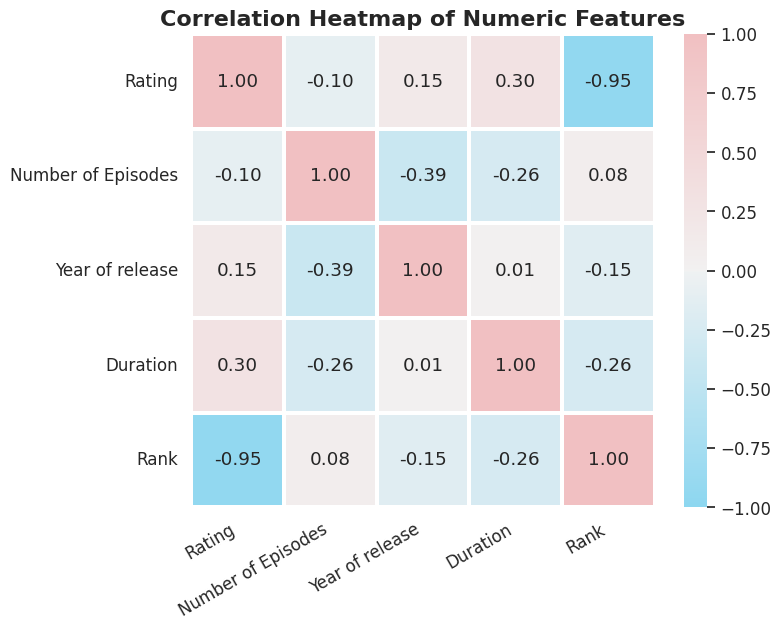

In [32]:
# 7) Genre vs average rating
if "genre_rating" in R and len(R["genre_rating"]):
    gr = R["genre_rating"].head(15).iloc[::-1].reset_index()
    fig = px.bar(gr, x="avg_rating", y="item", orientation="h", color="dramas", text="avg_rating",
                 color_continuous_scale=["#E8F5F7", "#A0C4FF", "#BDB2FF"])
    fig.update_traces(texttemplate="%{text:.2f}", textposition="outside",
                      marker_line_color="#888", marker_line_width=0.5)
    fig.update_xaxes(title="Average rating", range=[max(0, gr["avg_rating"].min() - 0.5), 10])
    fig.update_yaxes(title="")
    FIGS["genre_vs_rating"] = style_fig(fig, "Genre vs Average Rating (axis starts near the data)", 600)
    fig.show()
else:
    na("genre-vs-rating chart needs genre and rating")

# 8) Correlation heatmap
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(numeric_only=True)
    short = {c: (c if len(c) <= 22 else c[:20] + "...") for c in corr_cols}
    fig_h, ax = plt.subplots(figsize=(8, 6.5))
    cmap = sns.diverging_palette(220, 10, s=70, l=82, as_cmap=True)
    sns.heatmap(corr.rename(index=short, columns=short), annot=True, fmt=".2f", cmap=cmap,
                vmin=-1, vmax=1, linewidths=1.5, linecolor="white", ax=ax)
    ax.set_title("Correlation Heatmap of Numeric Features")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    na("heatmap needs at least two numeric columns")

In [33]:
# 9) Rating vs episodes
if EPS and RATING:
    sc = df[[EPS, RATING, TITLE]].dropna(subset=[EPS, RATING])
    cap = sc[EPS].quantile(0.99)
    sc_plot = sc[sc[EPS] <= cap]
    fig = px.scatter(sc_plot, x=EPS, y=RATING, hover_name=TITLE, opacity=0.65,
                     color_discrete_sequence=[PALETTE[2]])
    fig.update_traces(marker=dict(size=8, line=dict(width=0.5, color="#666")))
    slope, intercept = np.polyfit(sc_plot[EPS], sc_plot[RATING], 1)
    xs = np.array([sc_plot[EPS].min(), sc_plot[EPS].max()])
    fig.add_scatter(x=xs, y=slope * xs + intercept, mode="lines", name="Trend line",
                    line=dict(color=ACCENT, width=3))
    fig.update_xaxes(title="Number of episodes")
    fig.update_yaxes(title="Rating")
    FIGS["rating_vs_episodes"] = style_fig(fig, "Rating vs Episode Count", 520)
    fig.show()
else:
    na("scatter needs episodes and rating")

# 10) Top actors and directors
for key, label, color in (("cast_table", "Most Frequent Actors", PALETTE[4]),
                          ("director_table", "Directors with the Most Dramas", PALETTE[8])):
    if key in R:
        t = R[key].head(10).iloc[::-1].reset_index()
        fig = px.bar(t, x="dramas", y="item", orientation="h", text="dramas")
        fig.update_traces(marker_color=color, marker_line_color="#888",
                          marker_line_width=0.6, textposition="outside")
        fig.update_xaxes(title="Number of dramas")
        fig.update_yaxes(title="")
        FIGS[key] = style_fig(fig, label, 480)
        fig.show()
    else:
        na(label + " chart needs the matching column")

In [34]:
section("Correlation analysis")
if len(corr_cols) >= 2:
    cp = df[corr_cols].corr(method="pearson", numeric_only=True)
    cs = df[corr_cols].corr(method="spearman", numeric_only=True)
    R["corr_pearson"] = cp
    R["corr_spearman"] = cs
    print("Pearson (straight-line relationships):")
    display(cp)
    print("Spearman (rank-based, robust to outliers):")
    display(cs)

    # Rank is calculated from rating, so leave it out when picking the strongest link
    cs2 = cs.drop(index=RANK, columns=RANK) if RANK in cs.columns else cs
    pairs = cs2.where(np.triu(np.ones(cs2.shape, dtype=bool), k=1)).stack()
    pairs = pairs.sort_values(key=np.abs, ascending=False)
    if len(pairs):
        (a, b), v = pairs.index[0], pairs.iloc[0]
        strength = "strong" if abs(v) >= 0.6 else "moderate" if abs(v) >= 0.3 else "weak"
        direction = "positive" if v > 0 else "negative"
        print("Strongest link (excluding Rank):", a, "vs", b, "| Spearman", round(v, 2), "|", strength, direction)
        print("Reminder: correlation does not prove cause and effect.")
else:
    na("need at least two numeric columns")

section("Rating distribution analysis")
if RATING and df[RATING].notna().sum() > 20:
    r = df[RATING].dropna()
    print("Skewness:", round(r.skew(), 2))
    print("Kurtosis (excess):", round(r.kurt(), 2))
    stat, p = stats.normaltest(r)
    print("Normality test p-value:", round(p, 4), "->", "NOT a normal bell curve" if p < 0.05 else "may be normal")
    q = r.quantile([0.25, 0.5, 0.75])
    edges = sorted(set([-np.inf, q[0.25], q[0.5], q[0.75], np.inf]))
    band = pd.cut(r, edges, duplicates="drop")
    display(r.groupby(band, observed=True).agg(["count", "min", "max", "mean"]))
    print("Because this is a Top-250 list, ratings are squeezed into a narrow high range.")
else:
    na("rating distribution analysis needs rating")

Pearson (straight-line relationships):


,Rating,Number of Episodes,Year of release,Duration,Rank
Rating,1.00,-0.10,0.15,0.30,-0.95
Number of Episodes,-0.10,1.00,-0.39,-0.26,0.08
Year of release,0.15,-0.39,1.00,0.01,-0.15
Duration,0.30,-0.26,0.01,1.00,-0.26
Rank,-0.95,0.08,-0.15,-0.26,1.00


Spearman (rank-based, robust to outliers):


,Rating,Number of Episodes,Year of release,Duration,Rank
Rating,1.00,-0.06,0.13,0.21,-0.98
Number of Episodes,-0.06,1.00,-0.46,-0.12,0.07
Year of release,0.13,-0.46,1.00,0.14,-0.14
Duration,0.21,-0.12,0.14,1.00,-0.22
Rank,-0.98,0.07,-0.14,-0.22,1.00


Strongest link (excluding Rank): Number of Episodes vs Year of release | Spearman -0.46 | moderate negative
Reminder: correlation does not prove cause and effect.


Skewness: 0.88
Kurtosis (excess): 0.03
Normality test p-value: 0.0 -> NOT a normal bell curve


,count,min,max,mean
Rating,,,,
"(-inf, 8.3]",65,8.30,8.30,8.30
"(8.3, 8.5]",85,8.40,8.50,8.44
"(8.5, 8.7]",58,8.60,8.70,8.65
"(8.7, inf]",42,8.80,9.20,8.92


Because this is a Top-250 list, ratings are squeezed into a narrow high range.


In [35]:
section("Trend analysis: do ratings and episode counts change over time?")
if YEAR and RATING:
    t = df[[YEAR, RATING]].dropna()
    if t[YEAR].nunique() > 3:
        lr = stats.linregress(t[YEAR], t[RATING])
        R["rating_trend"] = lr
        print("Rating vs year: slope", round(lr.slope * 10, 3), "points per decade | r =",
              round(lr.rvalue, 2), "| p =", round(lr.pvalue, 4))
        print("->", "statistically meaningful trend" if lr.pvalue < 0.05 else "no statistically reliable trend")
else:
    na("rating trend needs year and rating")

if YEAR and EPS:
    t = df[[YEAR, EPS]].dropna()
    if t[YEAR].nunique() > 3:
        lr = stats.linregress(t[YEAR], t[EPS])
        R["episode_trend"] = lr
        print("Episodes vs year: slope", round(lr.slope * 10, 2), "episodes per decade | p =", round(lr.pvalue, 4))
        print("->", "statistically meaningful trend" if lr.pvalue < 0.05 else "no statistically reliable trend")

Rating vs year: slope 0.104 points per decade | r = 0.15 | p = 0.0147
-> statistically meaningful trend
Episodes vs year: slope -15.8 episodes per decade | p = 0.0
-> statistically meaningful trend


In [36]:
section("Genre-based comparison")
if GENRE and RATING:
    top_genres = R["genre_table"].head(8).index.tolist()
    gx = explode_items(GENRE)
    gx = gx[gx["item"].isin(top_genres)].dropna(subset=[RATING])
    if len(gx) > 20:
        fig = px.box(gx, x="item", y=RATING, color="item", points=False,
                     category_orders={"item": top_genres})
        fig.update_layout(showlegend=False)
        fig.update_xaxes(title="")
        fig.update_yaxes(title="Rating")
        FIGS["genre_boxplot"] = style_fig(fig, "Rating Spread in the 8 Most Common Genres", 500)
        fig.show()
        groups = [g[RATING].values for _, g in gx.groupby("item") if len(g) >= 5]
        if len(groups) >= 2:
            h, p = stats.kruskal(*groups)
            print("Kruskal-Wallis p =", round(p, 4), "->",
                  "genre rating differences are significant" if p < 0.05 else "genre rating differences are NOT significant")
else:
    na("genre comparison needs genre and rating")

section("Outlier analysis")
for col in outlier_bounds:
    lo, hi = outlier_bounds[col]
    out = df[(df[col] < lo) | (df[col] > hi)]
    print("-", col, ":", len(out), "outliers (fences", round(lo, 1), "to", round(hi, 1), ")")

if EPS and TITLE and EPS in outlier_bounds:
    long_ones = df[df[EPS] > outlier_bounds[EPS][1]].nlargest(5, EPS)
    if len(long_ones):
        display(pretty(long_ones[[c for c in (TITLE, YEAR, EPS, RATING) if c]]))
        print("Very long series are usually a different format (for example daily dramas), not errors.")

box_cols = [c for c in (RATING, EPS) if c]
if box_cols:
    fig = make_subplots(rows=1, cols=len(box_cols), subplot_titles=box_cols)
    for i, c in enumerate(box_cols, 1):
        fig.add_trace(go.Box(y=df[c], name=c, marker_color=PALETTE[i], boxpoints="outliers",
                             showlegend=False), row=1, col=i)
    FIGS["outliers"] = style_fig(fig, "Outlier View (box plots)", 450)
    fig.show()

Kruskal-Wallis p = 0.7538 -> genre rating differences are NOT significant


- Rating : 0 outliers (fences 7.7 to 9.3 )
- Number of Episodes : 51 outliers (fences 10.0 to 26.0 )
- Duration : 41 outliers (fences 45.0 to 85.0 )


,Name,Year of release,Number of Episodes,Rating
204,Ugly Alert,2013,133,8.30
85,Once Again,2020,100,8.60
202,Jumong,2006,81,8.30
117,Queen Seon Duk,2009,62,8.50
131,Dong Yi,2010,60,8.50


Very long series are usually a different format (for example daily dramas), not errors.


In [37]:
section("Platform / network performance comparison")
if NETWORK and RATING:
    nx = explode_items(NETWORK).dropna(subset=[RATING])
    q3 = df[RATING].quantile(0.75)
    perf = nx.groupby("item").agg(
        dramas=(RATING, "size"),
        avg_rating=(RATING, "mean"),
        median_rating=(RATING, "median"),
        high_rated_share=(RATING, lambda s: 100 * (s >= q3).mean()),
    )
    perf = perf[perf["dramas"] >= MIN_N].sort_values("avg_rating", ascending=False)
    R["platform_perf"] = perf
    print("Networks with at least", MIN_N, "rated dramas.")
    print("high_rated_share = % of its dramas in the overall top 25% (rating >=", round(q3, 2), ")")
    display(perf.head(12))

    top5 = perf.sort_values("dramas", ascending=False).head(5).index
    groups = [nx.loc[nx["item"] == n, RATING].values for n in top5 if (nx["item"] == n).sum() >= 5]
    if len(groups) >= 2:
        h, p = stats.kruskal(*groups)
        print("Kruskal-Wallis across the 5 biggest networks: p =", round(p, 4), "->",
              "significantly different" if p < 0.05 else "not significantly different")

    if len(perf):
        p10 = perf.head(10).iloc[::-1].reset_index()
        fig = px.bar(p10, x="high_rated_share", y="item", orientation="h", text="high_rated_share",
                     color="dramas", color_continuous_scale=["#E8F5F7", "#FFC6FF", "#BDB2FF"])
        fig.update_traces(texttemplate="%{text:.0f}%", textposition="outside",
                          marker_line_color="#888", marker_line_width=0.5)
        fig.update_xaxes(title="% of the network's dramas in the overall top 25%")
        fig.update_yaxes(title="")
        FIGS["platform_performance"] = style_fig(fig, "Which Networks Deliver the Most Top-Rated Dramas?", 520)
        fig.show()
else:
    na("platform comparison needs network and rating")

Networks with at least 5 rated dramas.
high_rated_share = % of its dramas in the overall top 25% (rating >= 8.7 )


,dramas,avg_rating,median_rating,high_rated_share
item,,,,
Netflix,56,8.66,8.70,51.79
tvN,77,8.60,8.50,38.96
SBS,37,8.54,8.50,40.54
jTBC,25,8.52,8.50,20.00
OCN,21,8.49,8.40,23.81
MBC,32,8.48,8.45,12.50
KBS2,29,8.47,8.40,10.34
Viki,6,8.45,8.40,16.67
ViuTV,5,8.40,8.40,0.00


Kruskal-Wallis across the 5 biggest networks: p = 0.0016 -> significantly different


In [38]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

feat_cols = [c for c in (RATING, EPS, YEAR, POPS, DUR) if c]
clus = df[feat_cols].dropna() if len(feat_cols) >= 2 else pd.DataFrame()
cluster_ready = False

if len(feat_cols) < 2 or len(clus) < 50:
    na("clustering needs at least 2 numeric features and 50 complete rows")
else:
    X = clus.copy()
    for c in (EPS, DUR):
        if c in X.columns:
            X[c] = np.log1p(X[c])
    Xs = StandardScaler().fit_transform(X)

    scores = {}
    for k in range(2, min(7, len(clus) // 10 + 2)):
        lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
        scores[k] = silhouette_score(Xs, lab)
    best_k = max(scores, key=scores.get)
    print("Silhouette score by number of clusters:", {k: round(v, 3) for k, v in scores.items()})
    print("Chosen number of clusters:", best_k)

    km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(Xs)
    clus = clus.assign(cluster=km.labels_)
    z = pd.DataFrame(km.cluster_centers_, columns=feat_cols)

    descriptions = {}
    for k in range(best_k):
        top = z.loc[k].abs().sort_values(ascending=False).head(2).index
        parts = [("high " if z.loc[k, c] > 0 else "low ") + c for c in top]
        descriptions[k] = ", ".join(parts)

    profile = clus.groupby("cluster")[feat_cols].mean()
    profile.insert(0, "dramas", clus.groupby("cluster").size())
    profile["what stands out"] = pd.Series(descriptions)
    R["cluster_profile"] = profile
    display(profile)
    cluster_ready = True

Silhouette score by number of clusters: {2: np.float64(0.339), 3: np.float64(0.348), 4: np.float64(0.35), 5: np.float64(0.364), 6: np.float64(0.366)}
Chosen number of clusters: 6


,dramas,Rating,Number of Episodes,Year of release,Duration,what stands out
cluster,,,,,,
0,63,8.84,14.97,"2,019.43",70.21,"high Rating, high Duration"
1,101,8.42,14.66,"2,019.83",67.65,"low Rating, high Year of release"
2,23,8.45,36.17,"2,018.48",34.26,"low Duration, high Number of Episodes"
3,9,8.50,66.33,"2,011.33",62.33,"high Number of Episodes, low Year of release"
4,43,8.44,18.40,"2,013.67",63.00,"low Year of release, low Rating"
5,11,8.35,11.09,"2,020.18",26.18,"low Duration, low Number of Episodes"


In [39]:
if cluster_ready:
    pca = PCA(n_components=2, random_state=42)
    pcs = pca.fit_transform(Xs)
    plot_df = pd.DataFrame({
        "PC1": pcs[:, 0],
        "PC2": pcs[:, 1],
        "cluster": ["Cluster " + str(c) + ": " + descriptions[c] for c in clus["cluster"]],
    })
    if TITLE:
        plot_df["title"] = df.loc[clus.index, TITLE].values
    fig = px.scatter(plot_df, x="PC1", y="PC2", color="cluster",
                     hover_name="title" if TITLE else None, opacity=0.75)
    fig.update_traces(marker=dict(size=8, line=dict(width=0.4, color="#666")))
    fig.update_xaxes(title="PC1 (" + str(round(pca.explained_variance_ratio_[0] * 100)) + "% of variation)")
    fig.update_yaxes(title="PC2 (" + str(round(pca.explained_variance_ratio_[1] * 100)) + "% of variation)")
    fig.update_layout(legend=dict(orientation="h", y=-0.25))
    FIGS["clusters"] = style_fig(fig, "K-Drama Clusters (2-D PCA view)", 600)
    fig.show()
    print("Each cluster is a group of similar dramas. 'what stands out' shows the features where it differs most from the average.")

Each cluster is a group of similar dramas. 'what stands out' shows the features where it differs most from the average.


In [40]:
analytic = [c for c in (RATING, EPS, YEAR, POPS, DUR) if c]
rows = []
for col in analytic:
    s = df[col].dropna()
    if len(s) == 0:
        continue
    mode = s.mode()
    rows.append({
        "variable": col,
        "count": len(s),
        "mean": s.mean(),
        "median": s.median(),
        "mode": mode.iloc[0] if len(mode) else np.nan,
        "std": s.std(),
        "min": s.min(),
        "Q1 (25%)": s.quantile(0.25),
        "Q3 (75%)": s.quantile(0.75),
        "max": s.max(),
        "skewness": s.skew(),
    })

stats_table = pd.DataFrame(rows).set_index("variable") if rows else pd.DataFrame()
if len(stats_table):
    display(stats_table)
else:
    na("no numeric analysis columns found")

,count,mean,median,mode,std,min,Q1 (25%),Q3 (75%),max,skewness
variable,,,,,,,,,,
Rating,250,8.53,8.50,8.30,0.22,8.30,8.30,8.70,9.20,0.88
Number of Episodes,250,19.06,16.00,16.00,13.25,1.00,16.00,20.00,133.00,4.53
Year of release,250,"2,018.26","2,019.00","2,021.00",3.26,"2,003.00","2,017.00","2,021.00","2,022.00",-1.32
Duration,250,62.41,65.00,70.00,14.96,15.00,60.00,70.00,100.00,-1.00


In [41]:
if len(stats_table):
    section("What do these numbers tell us?")
    for col in stats_table.index:
        r = stats_table.loc[col]
        if col == YEAR:
            print("-", col, ": data covers", int(r["min"]), "to", int(r["max"]),
                  "; half of all dramas are from", int(r["median"]), "or later.")
            continue
        if r["skewness"] > 0.5:
            shape = "a few unusually high values pull the average above the median (right-skewed)"
        elif r["skewness"] < -0.5:
            shape = "a few unusually low values pull the average below the median (left-skewed)"
        else:
            shape = "the distribution is fairly balanced"
        print("-", col, ": mean", round(r["mean"], 2), "vs median", round(r["median"], 2), "->", shape + ".")
        print("   The middle 50% of dramas fall between", round(r["Q1 (25%)"], 2), "and",
              round(r["Q3 (75%)"], 2), "(std", round(r["std"], 2), ").")

    if RATING in stats_table.index:
        sd = stats_table.loc[RATING, "std"]
        if sd < 0.6:
            print("\nIndustry reading: ratings are tightly bunched (std " + str(round(sd, 2)) +
                  "), because this is a Top-250 list. The gap between good and great is small.")
        else:
            print("\nIndustry reading: ratings vary clearly (std " + str(round(sd, 2)) + ").")

section("Correlation coefficients")
if len(corr_cols) >= 2:
    display(df[corr_cols].corr(numeric_only=True))
else:
    na("need at least two numeric columns")

- Rating : mean 8.53 vs median 8.5 -> a few unusually high values pull the average above the median (right-skewed).
   The middle 50% of dramas fall between 8.3 and 8.7 (std 0.22 ).
- Number of Episodes : mean 19.06 vs median 16.0 -> a few unusually high values pull the average above the median (right-skewed).
   The middle 50% of dramas fall between 16.0 and 20.0 (std 13.25 ).
- Year of release : data covers 2003 to 2022 ; half of all dramas are from 2019 or later.
- Duration : mean 62.41 vs median 65.0 -> a few unusually low values pull the average below the median (left-skewed).
   The middle 50% of dramas fall between 60.0 and 70.0 (std 14.96 ).

Industry reading: ratings are tightly bunched (std 0.22), because this is a Top-250 list. The gap between good and great is small.


,Rating,Number of Episodes,Year of release,Duration,Rank
Rating,1.00,-0.10,0.15,0.30,-0.95
Number of Episodes,-0.10,1.00,-0.39,-0.26,0.08
Year of release,0.15,-0.39,1.00,0.01,-0.15
Duration,0.30,-0.26,0.01,1.00,-0.26
Rank,-0.95,0.08,-0.15,-0.26,1.00


In [42]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

USE_POPULARITY = False
ml_ready = False

num_feats = [c for c in (EPS, YEAR, DUR) if c]
if USE_POPULARITY and POPS:
    num_feats.append(POPS)

if not RATING:
    na("ML needs a rating column")
else:
    ml = df.dropna(subset=[RATING]).reset_index(drop=True)
    if len(ml) < 150:
        na("not enough rated dramas for a trustworthy model: " + str(len(ml)))
    else:
        ml_ready = True

if ml_ready:
    train_idx, test_idx = train_test_split(ml.index, test_size=0.2, random_state=42)

    # genre vocabulary comes from TRAINING rows only (no leakage)
    vocab = []
    if GENRE:
        train_genres = [g for l in ml.loc[train_idx, GENRE + "__list"] for g in l]
        vocab = pd.Series(train_genres).value_counts().head(15).index.tolist()

    def make_X(frame):
        X = pd.DataFrame(index=frame.index)
        for c in num_feats:
            X[c] = frame[c]
        if NETWORK:
            X["network_main"] = frame[NETWORK + "__list"].map(lambda l: l[0] if l else np.nan)
        if C["content_rating"]:
            X["content_rating"] = frame[C["content_rating"]]
        for g in vocab:
            X["genre_" + g] = frame[GENRE + "__list"].map(lambda l, g=g: int(g in l))
        return X

    X_train, X_test = make_X(ml.loc[train_idx]), make_X(ml.loc[test_idx])
    y_train, y_test = ml.loc[train_idx, RATING], ml.loc[test_idx, RATING]

    cat_ml = [c for c in ("network_main", "content_rating") if c in X_train.columns]
    num_ml = [c for c in X_train.columns if c not in cat_ml]

    cat_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.02)),
    ])
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_ml),
        ("cat", cat_pipe, cat_ml),
    ])
    print("Features used:", list(X_train.columns))
    print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Features used: ['Number of Episodes', 'Year of release', 'Duration', 'network_main', 'content_rating', 'genre_Romance', 'genre_Drama', 'genre_Mystery', 'genre_Comedy', 'genre_Thriller', 'genre_Life', 'genre_Melodrama', 'genre_Action', 'genre_Fantasy', 'genre_Historical', 'genre_Law', 'genre_Supernatural', 'genre_Crime', 'genre_Psychological', 'genre_Political']
Training rows: 200 | Test rows: 50


In [43]:
if ml_ready:
    models = {
        "Baseline (always predict the mean)": DummyRegressor(strategy="mean"),
        "Ridge regression": Ridge(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    }
    results, fitted = [], {}
    for name, model in models.items():
        pipe = Pipeline([("pre", clone(pre)), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2").mean()
        results.append({
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
            "R2 (test)": r2_score(y_test, pred),
            "R2 (5-fold CV, train)": cv,
        })
        fitted[name] = (pipe, pred)
    res = pd.DataFrame(results).set_index("Model")
    R["ml_results"] = res
    display(res)

,MAE,RMSE,R2 (test),"R2 (5-fold CV, train)"
Model,,,,
Baseline (always predict the mean),0.21,0.24,-0.01,-0.06
Ridge regression,0.19,0.24,0.03,-0.08
Random Forest,0.18,0.23,0.13,0.15
Gradient Boosting,0.18,0.23,0.08,0.06


In [44]:
if ml_ready:
    real_models = res.drop(index="Baseline (always predict the mean)")
    best_name = real_models["RMSE"].idxmin()
    best_pipe, best_pred = fitted[best_name]
    base_rmse = res.loc["Baseline (always predict the mean)", "RMSE"]
    best_r2 = res.loc[best_name, "R2 (test)"]
    best_mae = res.loc[best_name, "MAE"]
    R["ml_best"] = best_name
    print("Best model:", best_name, "| R2 =", round(best_r2, 3), "| MAE =", round(best_mae, 3),
          "| RMSE =", round(res.loc[best_name, "RMSE"], 3))
    gain = 100 * (base_rmse - res.loc[best_name, "RMSE"]) / base_rmse
    print("Change in RMSE versus the baseline:", round(gain, 1), "% (positive = better than baseline)")

    fig = go.Figure()
    fig.add_scatter(x=y_test, y=best_pred, mode="markers", name="Dramas", opacity=0.7,
                    marker=dict(color=PALETTE[2], size=8, line=dict(width=0.5, color="#666")))
    lo = float(min(y_test.min(), best_pred.min()))
    hi = float(max(y_test.max(), best_pred.max()))
    fig.add_scatter(x=[lo, hi], y=[lo, hi], mode="lines", name="Perfect prediction",
                    line=dict(color=ACCENT, dash="dash"))
    fig.update_xaxes(title="Actual rating")
    fig.update_yaxes(title="Predicted rating")
    FIGS["ml_actual_vs_pred"] = style_fig(fig, best_name + ": Actual vs Predicted (test set)", 520)
    fig.show()

    try:
        names = [n.split("__", 1)[-1] for n in best_pipe.named_steps["pre"].get_feature_names_out()]
        model = best_pipe.named_steps["model"]
        imp = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_)
        fi = pd.Series(imp, index=names).sort_values(ascending=False).head(12).iloc[::-1].reset_index()
        fi.columns = ["feature", "importance"]
        fig = px.bar(fi, x="importance", y="feature", orientation="h")
        fig.update_traces(marker_color=PALETTE[0], marker_line_color="#888", marker_line_width=0.5)
        FIGS["ml_importance"] = style_fig(fig, "What the Model Relies On Most", 500)
        fig.show()
    except Exception as exc:
        print("Feature importance not available:", exc)

    print("\nHow to read this honestly:")
    print("- R2 =", round(best_r2, 2), ": the model explains about", round(max(best_r2, 0) * 100),
          "% of rating differences on unseen dramas.")
    print("- MAE =", round(best_mae, 2), ": predictions are off by about", round(best_mae, 2), "rating points.")
    if best_r2 <= 0:
        print("- WARNING: the model is NOT better than predicting the average, so these features do not predict ratings here.")
    elif best_r2 < 0.3:
        print("- The fit is modest. Ratings depend on things this dataset cannot capture (story, acting, marketing).")
    print("- Limits: only 250 top-rated dramas, ratings barely vary, and this shows association, not cause.")

Best model: Random Forest | R2 = 0.127 | MAE = 0.18 | RMSE = 0.225
Change in RMSE versus the baseline: 7.2 % (positive = better than baseline)



How to read this honestly:
- R2 = 0.13 : the model explains about 13 % of rating differences on unseen dramas.
- MAE = 0.18 : predictions are off by about 0.18 rating points.
- The fit is modest. Ratings depend on things this dataset cannot capture (story, acting, marketing).
- Limits: only 250 top-rated dramas, ratings barely vary, and this shows association, not cause.


In [45]:
insights = []


def add(title, detail):
    insights.append((title, detail))


span = ""
if YEAR and df[YEAR].notna().any():
    span = " spanning " + str(int(df[YEAR].min())) + " to " + str(int(df[YEAR].max()))
add("Dataset scale", "The cleaned dataset holds " + str(len(df)) + " dramas" + span + ".")

if "year_counts" in R:
    yc = R["year_counts"]
    share = 100 * yc.max() / yc.sum()
    add("Most productive year", str(R["peak_year"]) + " had the most dramas (" + str(int(yc.max())) +
        "), which is " + str(round(share, 1)) + "% of dramas with a known year.")

if "year_full" in R and len(R["year_full"]) >= 6:
    full = R["year_full"]
    half = len(full) // 2
    early, late = int(full.iloc[:half].sum()), int(full.iloc[half:].sum())
    if early > 0:
        change = 100 * (late - early) / early
        add("Industry growth", "The later half of the period (" + str(int(full.index[half])) + " to " +
            str(int(full.index[-1])) + ") has " + str(late) + " dramas versus " + str(early) +
            " in the earlier half (" + str(round(change)) + "% change). Biggest single-year jump: " +
            str(R.get("biggest_jump_year", "n/a")) + ".")

if "genre_table" in R and len(R["genre_table"]):
    gt = R["genre_table"]
    top3 = ", ".join(g + " (" + str(int(n)) + ")" for g, n in gt["dramas"].head(3).items())
    add("Dominant genres", "The three most common genres are " + top3 + ". '" + gt.index[0] +
        "' appears in " + str(round(100 * gt["dramas"].iloc[0] / len(df))) + "% of dramas.")

if "genre_rating" in R and len(R["genre_rating"]):
    gr = R["genre_rating"]
    add("Best and lowest rated genres", "Among genres with at least " + str(MIN_N) + " dramas, '" + gr.index[0] +
        "' has the highest average rating (" + str(round(gr["avg_rating"].iloc[0], 2)) + ") and '" + gr.index[-1] +
        "' the lowest (" + str(round(gr["avg_rating"].iloc[-1], 2)) + ").")

if "avg_rating" in R:
    r = df[RATING].dropna()
    add("Typical rating", "The average rating is " + str(round(R["avg_rating"], 2)) + " (median " +
        str(round(R["median_rating"], 2)) + "); the middle 50% of dramas score between " +
        str(round(r.quantile(0.25), 2)) + " and " + str(round(r.quantile(0.75), 2)) + ".")

if "top10" in R and len(R["top10"]):
    t = R["top10"].iloc[0]
    add("Highest-rated drama", "'" + str(t[TITLE]) + "' has the top rating (" + str(round(t[RATING], 1)) +
        "). The top 10 range from " + str(round(R["top10"][RATING].min(), 1)) + " to " +
        str(round(R["top10"][RATING].max(), 1)) + ".")

if "network_table" in R and len(R["network_table"]):
    nt = R["network_table"]
    share3 = 100 * nt["dramas"].head(3).sum() / max(nt["dramas"].sum(), 1)
    add("Network concentration", "'" + nt.index[0] + "' leads with " + str(int(nt["dramas"].iloc[0])) +
        " dramas (" + str(round(100 * nt["dramas"].iloc[0] / len(df))) + "% of the dataset); the top 3 networks hold " +
        str(round(share3)) + "% of all network credits.")

print(len(insights), "insights so far. Run the next cell to add more.")

8 insights so far. Run the next cell to add more.


In [46]:
if "platform_perf" in R and len(R["platform_perf"]):
    pp = R["platform_perf"]
    add("Strongest rated network", "Among networks with at least " + str(MIN_N) + " rated dramas, '" + pp.index[0] +
        "' has the best average rating (" + str(round(pp["avg_rating"].iloc[0], 2)) + "), with " +
        str(round(pp["high_rated_share"].iloc[0])) + "% of its dramas in the overall top 25%.")

if EPS and df[EPS].notna().any():
    e = df[EPS].dropna()
    add("Typical series length", "The median drama has " + str(round(e.median())) + " episodes; " +
        str(round(100 * (e <= 16).mean())) + "% have 16 episodes or fewer, while the longest runs " +
        str(int(e.max())) + " episodes.")

if "eps_rating_corr" in R:
    sr = R["eps_rating_corr"][1]
    word = "weak" if abs(sr) < 0.3 else "moderate" if abs(sr) < 0.6 else "strong"
    sign = "positive" if sr > 0 else "negative"
    add("Length vs quality", "Episode count and rating have a " + word + " " + sign +
        " relationship (Spearman " + str(round(sr, 2)) + "). Length alone does not explain quality.")

if "rating_trend" in R:
    lr = R["rating_trend"]
    sig = "statistically significant" if lr.pvalue < 0.05 else "not statistically significant"
    add("Rating trend over time", "Average ratings change by " + str(round(lr.slope * 10, 3)) +
        " points per decade (" + sig + ").")

if "cast_table" in R and len(R["cast_table"]):
    ct = R["cast_table"]
    extra = ""
    if "avg_rating" in ct and pd.notna(ct["avg_rating"].iloc[0]):
        extra = " (average rating " + str(round(ct["avg_rating"].iloc[0], 2)) + ")"
    add("Most frequent actor", "'" + ct.index[0] + "' appears in " + str(int(ct["dramas"].iloc[0])) + " dramas" + extra + ".")

if "director_table" in R and len(R["director_table"]):
    dt = R["director_table"]
    add("Most prolific director", "'" + dt.index[0] + "' directed " + str(int(dt["dramas"].iloc[0])) +
        " dramas in this dataset.")

if RATING and df[RATING].notna().sum() > 30:
    cut = df[RATING].quantile(0.75)
    high, rest = df[df[RATING] >= cut], df[df[RATING] < cut]
    bits = []
    if EPS:
        bits.append("median episodes " + str(round(high[EPS].median())) + " vs " + str(round(rest[EPS].median())))
    if YEAR:
        bits.append("median release year " + str(round(high[YEAR].median())) + " vs " + str(round(rest[YEAR].median())))
    if DUR:
        bits.append("median episode length " + str(round(high[DUR].median())) + " vs " + str(round(rest[DUR].median())) + " min")
    if bits and len(rest):
        add("Profile of top-25% rated dramas", "Compared with the rest (rating >= " + str(round(cut, 2)) + "): " + "; ".join(bits) + ".")

worst = before_after["missing AFTER cleaning"].sort_values(ascending=False)
if len(worst) and worst.iloc[0] > 0:
    add("Data completeness", "The most incomplete column is '" + str(worst.index[0]) + "' with " +
        str(int(worst.iloc[0])) + " missing values. Findings that use it rely only on the rows where it exists.")

lines = [("**" + str(i) + ". " + t + "**: " + d + "\n") for i, (t, d) in enumerate(insights, 1)]
display(Markdown("\n".join(lines)))
print("Total data-backed insights:", len(insights))

**1. Dataset scale**: The cleaned dataset holds 250 dramas spanning 2003 to 2022.

**2. Most productive year**: 2021 had the most dramas (39), which is 15.6% of dramas with a known year.

**3. Industry growth**: The later half of the period (2013 to 2022) has 234 dramas versus 16 in the earlier half (1362% change). Biggest single-year jump: 2017.

**4. Dominant genres**: The three most common genres are Romance (136), Drama (129), Mystery (90). 'Romance' appears in 54% of dramas.

**5. Best and lowest rated genres**: Among genres with at least 5 dramas, 'Friendship' has the highest average rating (8.79) and 'Business' the lowest (8.49).

**6. Typical rating**: The average rating is 8.53 (median 8.5); the middle 50% of dramas score between 8.3 and 8.7.

**7. Highest-rated drama**: 'Move to Heaven' has the top rating (9.2). The top 10 range from 9.0 to 9.2.

**8. Network concentration**: 'tvN' leads with 77 dramas (31% of the dataset); the top 3 networks hold 55% of all network credits.

**9. Strongest rated network**: Among networks with at least 5 rated dramas, 'Netflix' has the best average rating (8.66), with 52% of its dramas in the overall top 25%.

**10. Typical series length**: The median drama has 16 episodes; 70% have 16 episodes or fewer, while the longest runs 133 episodes.

**11. Length vs quality**: Episode count and rating have a weak negative relationship (Spearman -0.06). Length alone does not explain quality.

**12. Rating trend over time**: Average ratings change by 0.104 points per decade (statistically significant).

**13. Most frequent actor**: 'Lee Joon Hyuk' appears in 8 dramas (average rating 8.61).

**14. Most prolific director**: 'Kim Won Suk' directed 6 dramas in this dataset.

**15. Profile of top-25% rated dramas**: Compared with the rest (rating >= 8.7): median episodes 16 vs 16; median release year 2020 vs 2019; median episode length 70 vs 65 min.

**16. Data completeness**: The most incomplete column is 'Content Rating' with 5 missing values. Findings that use it rely only on the rows where it exists.


Total data-backed insights: 16


In [47]:
def kpi(label, value, sub=""):
    return ("<div style='flex:1;min-width:190px;background:linear-gradient(135deg,#ffffff,#f3efff);"
            "border:1px solid #d9d3f5;border-radius:14px;padding:16px 18px;'>"
            "<div style='color:#6b6b8a;font-size:13px;text-transform:uppercase'>" + label + "</div>"
            "<div style='color:" + ACCENT + ";font-size:24px;font-weight:700;margin:4px 0'>" + str(value) + "</div>"
            "<div style='color:#888;font-size:12px'>" + sub + "</div></div>")


cards = [kpi("Total dramas", len(df), "after cleaning")]
if "avg_rating" in R:
    cards.append(kpi("Average rating", round(R["avg_rating"], 2), "median " + str(round(R["median_rating"], 2))))
else:
    cards.append(kpi("Average rating", "n/a", "no rating column"))
if "genre_table" in R and len(R["genre_table"]):
    cards.append(kpi("Most common genre", R["genre_table"].index[0], str(int(R["genre_table"]["dramas"].iloc[0])) + " dramas"))
else:
    cards.append(kpi("Most common genre", "n/a", ""))
if "top10" in R and len(R["top10"]):
    cards.append(kpi("Highest-rated drama", R["top10"][TITLE].iloc[0], "rating " + str(round(R["top10"][RATING].iloc[0], 1))))
else:
    cards.append(kpi("Highest-rated drama", "n/a", ""))
if "peak_year" in R:
    cards.append(kpi("Most productive year", R["peak_year"], str(int(R["year_counts"].max())) + " dramas"))
else:
    cards.append(kpi("Most productive year", "n/a", ""))

display(HTML("<div style='display:flex;flex-wrap:wrap;gap:12px;margin:10px 0'>" + "".join(cards) + "</div>"))

In [48]:
def na_panel(fig, row, col, msg="Not available in this dataset"):
    fig.add_trace(go.Scatter(x=[0], y=[0], mode="text", text=[msg], showlegend=False), row=row, col=col)
    fig.update_xaxes(visible=False, row=row, col=col)
    fig.update_yaxes(visible=False, row=row, col=col)


dash = make_subplots(
    rows=3, cols=2, vertical_spacing=0.12, horizontal_spacing=0.14,
    specs=[[{"type": "xy"}, {"type": "domain"}], [{"type": "xy"}, {"type": "xy"}], [{"type": "xy"}, {"type": "xy"}]],
    subplot_titles=("Top 10 dramas by rating", "Genre distribution (top 8)", "Production trend",
                    "Average rating by genre", "Rating distribution", "Top networks by number of dramas"))

if "top10" in R:
    t = R["top10"].iloc[::-1]
    dash.add_bar(x=t[RATING], y=t[TITLE], orientation="h", marker_color=PALETTE[2],
                 text=t[RATING].round(1), textposition="outside", showlegend=False, row=1, col=1)
else:
    na_panel(dash, 1, 1)

if "genre_table" in R and len(R["genre_table"]) >= 2:
    gt = R["genre_table"]["dramas"]
    top8, other = gt.head(8), gt.iloc[8:].sum()
    labels = list(top8.index) + (["Other genres"] if other > 0 else [])
    values = list(top8.values) + ([other] if other > 0 else [])
    dash.add_trace(go.Pie(labels=labels, values=values, hole=0.5, textinfo="label+percent", showlegend=False,
                          marker=dict(colors=PALETTE, line=dict(color="white", width=2))), row=1, col=2)
else:
    dash.add_annotation(text="Not available", x=0.82, y=0.92, xref="paper", yref="paper", showarrow=False)

if "year_full" in R:
    full = R["year_full"]
    dash.add_bar(x=full.index, y=full.values, marker_color=PALETTE[0], showlegend=False, row=2, col=1)
    dash.add_scatter(x=full.index, y=full.rolling(3, center=True, min_periods=1).mean(), mode="lines",
                     line=dict(color=ACCENT, width=3), showlegend=False, row=2, col=1)
else:
    na_panel(dash, 2, 1)

if "genre_rating" in R and len(R["genre_rating"]):
    gr = R["genre_rating"].head(10).iloc[::-1]
    dash.add_bar(x=gr["avg_rating"], y=gr.index, orientation="h", marker_color=PALETTE[1], showlegend=False, row=2, col=2)
    dash.update_xaxes(range=[max(0, gr["avg_rating"].min() - 0.5), 10], row=2, col=2)
else:
    na_panel(dash, 2, 2)

if RATING and df[RATING].notna().sum() > 5:
    dash.add_histogram(x=df[RATING].dropna(), nbinsx=20, marker_color=PALETTE[3], showlegend=False, row=3, col=1)
else:
    na_panel(dash, 3, 1)

if "network_table" in R:
    nt = R["network_table"].head(10).iloc[::-1]
    dash.add_bar(x=nt["dramas"], y=nt.index, orientation="h", marker_color=PALETTE[4], showlegend=False, row=3, col=2)
else:
    na_panel(dash, 3, 2)

dash.update_layout(title=dict(text="<b>K-Drama Analytics Dashboard</b>", x=0.02, font=dict(size=24)),
                   height=1250, font=dict(family="Arial", size=12),
                   plot_bgcolor="white", paper_bgcolor="white", margin=dict(l=60, r=30, t=100, b=40))
dash.update_xaxes(showgrid=False)
dash.update_yaxes(gridcolor="#eee")
FIGS["dashboard"] = dash
dash.show()

In [49]:
L = []
L.append("# K-Drama Analytics: Final Report\n")
L.append("## 1. Project overview")
L.append("This project cleans a Kaggle K-Drama dataset and explores it with statistics, visualisation, "
         "clustering and a rating-prediction experiment. Every number below was computed from the data.\n")

L.append("## 2. Dataset description")
L.append("- File: " + str(csv_path))
L.append("- Original size: " + str(df_raw.shape[0]) + " rows x " + str(df_raw.shape[1]) +
         " columns; after cleaning: " + str(len(df)) + " dramas")
found = [k + " = " + v for k, v in C.items() if v and k != "pop_score"]
L.append("- Columns recognised: " + ", ".join(found))
unavailable = [k for k in ("year", "rating", "episodes", "genre", "network", "cast", "director", "popularity") if not C.get(k)]
L.append("- Not available in this dataset: " + (", ".join(unavailable) if unavailable else "nothing important") + "\n")

L.append("## 3. Data cleaning summary")
for row in cleaning_log:
    L.append("- " + row["Step"] + ": " + row["Outcome"])
L.append("")

L.append("## 4. Key findings")
for i, (t, d) in enumerate(insights[:8], 1):
    L.append(str(i) + ". **" + t + "**: " + d)
L.append("")
print("Report part 1 ready.")

Report part 1 ready.


In [50]:
L.append("## 5. Important visualizations")
L.append("Top-10 rated dramas, common genres, production by year, rating and episode distributions, network "
         "comparison, genre vs rating, correlation heatmap, rating vs episodes, actors and directors, "
         "cluster map and the interactive dashboard.\n")

L.append("## 6. Statistical observations")
if len(stats_table):
    for col in stats_table.index:
        if col == YEAR:
            continue
        r = stats_table.loc[col]
        L.append("- " + col + ": mean " + str(round(r["mean"], 2)) + ", median " + str(round(r["median"], 2)) +
                 ", std " + str(round(r["std"], 2)) + ", range " + str(round(r["min"], 2)) + " to " + str(round(r["max"], 2)))
if "eps_rating_corr" in R:
    L.append("- Episodes vs rating: Pearson " + str(round(R["eps_rating_corr"][0], 2)) +
             ", Spearman " + str(round(R["eps_rating_corr"][1], 2)))
L.append("")

L.append("## 7. Business insights")
for t, d in insights[8:]:
    L.append("- **" + t + "**: " + d)
if "ml_results" in R:
    b = R["ml_results"].loc[R["ml_best"]]
    L.append("- **Prediction experiment**: " + R["ml_best"] + " reached R2 " + str(round(b["R2 (test)"], 2)) +
             " and MAE " + str(round(b["MAE"], 2)) + " on unseen dramas.")
L.append("")

L.append("## 8. Limitations")
L.append("- This is a Top-250 list, so every drama is already highly rated and ratings barely vary.")
L.append("- Ratings come from one website and can be inflated when few people vote.")
L.append("- Results show association, not cause and effect.")
L.append("- No popularity column exists, so rating vs popularity could not be studied.")
L.append("- Genres, actors and networks are multi-valued, so group counts overlap.\n")

L.append("## 9. Future improvements")
L.append("- Add a larger dataset that includes lower-rated dramas to avoid selection bias.")
L.append("- Add viewership or social-media data to measure success beyond ratings.")
L.append("- Use the synopsis and tags with NLP to find which story themes score well.")
L.append("- Build a recommender system and publish the dashboard as a Streamlit app.")

report_md = "\n".join(L)
display(Markdown(report_md))

# K-Drama Analytics: Final Report

## 1. Project overview
This project cleans a Kaggle K-Drama dataset and explores it with statistics, visualisation, clustering and a rating-prediction experiment. Every number below was computed from the data.

## 2. Dataset description
- File: /root/.cache/kagglehub/datasets/ahbab911/top-250-korean-dramas-kdrama-dataset/versions/1/kdrama.csv
- Original size: 250 rows x 17 columns; after cleaning: 250 dramas
- Columns recognised: content_rating = Content Rating, title = Name, year = Year of release, date = Aired Date, rating = Rating, episodes = Number of Episodes, network = Original Network, genre = Genre, cast = Cast, director = Director, rank = Rank, duration = Duration
- Not available in this dataset: popularity

## 3. Data cleaning summary
- Text normalisation: 14 text columns tidied; 0 placeholder cells set to missing
- Duplicate removal: 0 identical rows + 0 same-title/same-year rows removed
- Rows without a title: 0 rows removed
- Data-type correction: 6 conversions applied
- Category harmonisation (Content Rating): 0 variant spellings merged
- Multi-value split (Genre): 0 spelling variants merged -> 29 distinct items
- Multi-value split (Original Network): 0 spelling variants merged -> 23 distinct items
- Multi-value split (Cast): 0 spelling variants merged -> 829 distinct items
- Multi-value split (Director): 0 spelling variants merged -> 183 distinct items
- Validation and outliers: 0 impossible values set to missing; outliers flagged and kept
- Missing-value policy: no imputation for analysis; each analysis uses available rows only

## 4. Key findings
1. **Dataset scale**: The cleaned dataset holds 250 dramas spanning 2003 to 2022.
2. **Most productive year**: 2021 had the most dramas (39), which is 15.6% of dramas with a known year.
3. **Industry growth**: The later half of the period (2013 to 2022) has 234 dramas versus 16 in the earlier half (1362% change). Biggest single-year jump: 2017.
4. **Dominant genres**: The three most common genres are Romance (136), Drama (129), Mystery (90). 'Romance' appears in 54% of dramas.
5. **Best and lowest rated genres**: Among genres with at least 5 dramas, 'Friendship' has the highest average rating (8.79) and 'Business' the lowest (8.49).
6. **Typical rating**: The average rating is 8.53 (median 8.5); the middle 50% of dramas score between 8.3 and 8.7.
7. **Highest-rated drama**: 'Move to Heaven' has the top rating (9.2). The top 10 range from 9.0 to 9.2.
8. **Network concentration**: 'tvN' leads with 77 dramas (31% of the dataset); the top 3 networks hold 55% of all network credits.

## 5. Important visualizations
Top-10 rated dramas, common genres, production by year, rating and episode distributions, network comparison, genre vs rating, correlation heatmap, rating vs episodes, actors and directors, cluster map and the interactive dashboard.

## 6. Statistical observations
- Rating: mean 8.53, median 8.5, std 0.22, range 8.3 to 9.2
- Number of Episodes: mean 19.06, median 16.0, std 13.25, range 1.0 to 133.0
- Duration: mean 62.41, median 65.0, std 14.96, range 15.0 to 100.0
- Episodes vs rating: Pearson -0.1, Spearman -0.06

## 7. Business insights
- **Strongest rated network**: Among networks with at least 5 rated dramas, 'Netflix' has the best average rating (8.66), with 52% of its dramas in the overall top 25%.
- **Typical series length**: The median drama has 16 episodes; 70% have 16 episodes or fewer, while the longest runs 133 episodes.
- **Length vs quality**: Episode count and rating have a weak negative relationship (Spearman -0.06). Length alone does not explain quality.
- **Rating trend over time**: Average ratings change by 0.104 points per decade (statistically significant).
- **Most frequent actor**: 'Lee Joon Hyuk' appears in 8 dramas (average rating 8.61).
- **Most prolific director**: 'Kim Won Suk' directed 6 dramas in this dataset.
- **Profile of top-25% rated dramas**: Compared with the rest (rating >= 8.7): median episodes 16 vs 16; median release year 2020 vs 2019; median episode length 70 vs 65 min.
- **Data completeness**: The most incomplete column is 'Content Rating' with 5 missing values. Findings that use it rely only on the rows where it exists.
- **Prediction experiment**: Random Forest reached R2 0.13 and MAE 0.18 on unseen dramas.

## 8. Limitations
- This is a Top-250 list, so every drama is already highly rated and ratings barely vary.
- Ratings come from one website and can be inflated when few people vote.
- Results show association, not cause and effect.
- No popularity column exists, so rating vs popularity could not be studied.
- Genres, actors and networks are multi-valued, so group counts overlap.

## 9. Future improvements
- Add a larger dataset that includes lower-rated dramas to avoid selection bias.
- Add viewership or social-media data to measure success beyond ratings.
- Use the synopsis and tags with NLP to find which story themes score well.
- Build a recommender system and publish the dashboard as a Streamlit app.

In [51]:
OUT_DIR = "kdrama_outputs"
os.makedirs(os.path.join(OUT_DIR, "charts"), exist_ok=True)

export_df = df.copy()
for col in [c[:-6] for c in export_df.columns if c.endswith("__list")]:
    export_df[col] = export_df[col + "__list"].map(lambda l: ", ".join(l) if l else np.nan)
export_df = export_df.drop(columns=[c for c in export_df.columns if c.endswith("__list")])
export_df.to_csv(os.path.join(OUT_DIR, "kdrama_cleaned.csv"), index=False)

pd.DataFrame(cleaning_log).to_csv(os.path.join(OUT_DIR, "cleaning_log.csv"), index=False)
if len(stats_table):
    stats_table.to_csv(os.path.join(OUT_DIR, "statistics_summary.csv"))

with open(os.path.join(OUT_DIR, "insights.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(str(i) + ". " + t + ": " + d for i, (t, d) in enumerate(insights, 1)))
with open(os.path.join(OUT_DIR, "final_report.md"), "w", encoding="utf-8") as f:
    f.write(report_md)

for name, fig in FIGS.items():
    if name == "dashboard":
        path = os.path.join(OUT_DIR, "dashboard.html")
    else:
        path = os.path.join(OUT_DIR, "charts", name + ".html")
    fig.write_html(path, include_plotlyjs="cdn")

zip_name = "kdrama_outputs.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for folder, _, files_in in os.walk(OUT_DIR):
        for fn in files_in:
            full_path = os.path.join(folder, fn)
            z.write(full_path, os.path.relpath(full_path, OUT_DIR))

print("Saved files in", OUT_DIR, "and created", zip_name)
if IN_COLAB:
    files.download(zip_name)
    files.download(os.path.join(OUT_DIR, "kdrama_cleaned.csv"))
else:
    print("Not running in Colab: find the files in the working folder.")

Saved files in kdrama_outputs and created kdrama_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>